# Lab 6: Association Rule Mining with Apriori and FP-Growth

**Student Name:** Pranavi Balakulla
**Course:** MSCS 634
**Lab Assignment:** Lab 6 – Association Rule Mining with Apriori and FP-Growth

**Objective:** Mine frequent itemsets from real retail transactions with Apriori and FP-Growth, generate association rules
(support, confidence, lift), visualize the patterns with Seaborn, and compare the two algorithms on speed and output.

## Step 1: Data Preparation

### 1.1 Setup
Install and import the libraries. `mlxtend` provides the `apriori`, `fpgrowth` and `association_rules` functions.
Warnings are silenced so the notebook output stays readable (the Jupyter client emits a harmless
`DeprecationWarning` on every cell in recent Python versions).

In [1]:
# Install the required packages (quiet mode)
%pip install -q pandas openpyxl matplotlib seaborn mlxtend

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Suppress noisy library deprecation warnings so outputs stay readable
import warnings
warnings.filterwarnings("ignore")

# Standard library
import os
import time
import zipfile
import urllib.request

# Data handling and visualization
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Association rule mining
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Consistent plot styling and wide table display
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

### 1.2 Load the dataset
The **UCI Online Retail dataset** (Chen, 2015) contains every transaction of a UK-based online gift retailer between
01/12/2010 and 09/12/2011. Each row is one product line on an invoice, which is exactly the item-level
transaction format that Apriori and FP-Growth need: the invoice is the transaction and the product description is the item.

The cell below downloads the official UCI zip file. If the UCI site cannot be reached, it falls back to an identical
CSV copy of the same dataset published in the Databricks *Spark: The Definitive Guide* GitHub repository
(same 541,909 rows and 8 columns).

In [3]:
# Primary source: UCI Machine Learning Repository
UCI_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
# Fallback: identical copy of the dataset hosted on GitHub
MIRROR_URL = ("https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/"
              "master/data/retail-data/all/online-retail-dataset.csv")

def load_online_retail():
    """Load the Online Retail data from UCI, falling back to the GitHub mirror."""
    try:
        zip_path = "online_retail.zip"
        if not os.path.exists(zip_path):
            urllib.request.urlretrieve(UCI_URL, zip_path)
        with zipfile.ZipFile(zip_path) as archive:
            excel_file = next(n for n in archive.namelist() if n.lower().endswith(".xlsx"))
            archive.extract(excel_file, ".")
        print("Loaded from: UCI Machine Learning Repository (Excel)")
        return pd.read_excel(excel_file, dtype={"InvoiceNo": str, "StockCode": str})
    except Exception as err:
        print(f"UCI download unavailable ({type(err).__name__}); using GitHub mirror instead.")
        csv_path = "online-retail-dataset.csv"
        if not os.path.exists(csv_path):
            urllib.request.urlretrieve(MIRROR_URL, csv_path)
        print("Loaded from: GitHub mirror (CSV)")
        return pd.read_csv(csv_path, dtype={"InvoiceNo": str, "StockCode": str})

raw = load_online_retail()
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])  # same type regardless of source
raw.head()

UCI download unavailable (URLError); using GitHub mirror instead.
Loaded from: GitHub mirror (CSV)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 1.3 Dataset structure
Before cleaning, inspect the size, column types, missing values and the main quirks of the data.

| Column | Meaning |
|---|---|
| `InvoiceNo` | Invoice (transaction) ID. IDs starting with **C** are cancellations |
| `StockCode` | Product code. A few codes are not products (postage, bank charges, manual adjustments) |
| `Description` | Product name – used as the **item** for mining |
| `Quantity` | Units on the line. Negative values are returns/adjustments |
| `InvoiceDate` | Date and time of the invoice |
| `UnitPrice` | Price per unit in GBP |
| `CustomerID` | Customer ID (missing for guest checkouts) |
| `Country` | Customer's country |

In [4]:
# Overall size, column types and non-null counts
print("Rows x columns:", raw.shape)
raw.info()

Rows x columns: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


In [5]:
# Summary of the data quality issues the cleaning step must handle
profile = pd.Series({
    "Unique invoices": raw["InvoiceNo"].nunique(),
    "Unique products (descriptions)": raw["Description"].nunique(),
    "Unique customers": raw["CustomerID"].nunique(),
    "Countries": raw["Country"].nunique(),
    "Missing Description": raw["Description"].isna().sum(),
    "Missing CustomerID": raw["CustomerID"].isna().sum(),
    "Cancelled lines (InvoiceNo starts with C)": raw["InvoiceNo"].str.startswith("C").sum(),
    "Lines with Quantity <= 0": (raw["Quantity"] <= 0).sum(),
    "Lines with UnitPrice <= 0": (raw["UnitPrice"] <= 0).sum(),
    "Exact duplicate rows": raw.duplicated().sum(),
}, name="Value")
print("Date range:", raw["InvoiceDate"].min().date(), "to", raw["InvoiceDate"].max().date())
profile.to_frame()

Date range: 2010-12-01 to 2011-12-09


,Value
Unique invoices,25900
Unique products (descriptions),4223
Unique customers,4372
Countries,38
Missing Description,1454
Missing CustomerID,135080
Cancelled lines (InvoiceNo starts with C),9288
Lines with Quantity <= 0,10624
Lines with UnitPrice <= 0,2517
Exact duplicate rows,5268


In [6]:
# Numeric summary: Quantity and UnitPrice contain negatives and extreme outliers
raw[["Quantity", "UnitPrice"]].describe().round(2)

,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,38970.00


**What the structure tells us**

- The raw file has **541,909 product lines** from **25,900 invoices**, **4,223 product descriptions**, **4,372 customers**
  and **38 countries**, covering 1 Dec 2010 – 9 Dec 2011.
- **135,080 lines (25%) have no `CustomerID`** and 1,454 have no `Description`. They cannot be linked to an identifiable
  transaction or item, so they are dropped.
- **9,288 lines are cancellations** (`InvoiceNo` starting with C). Together with other adjustments, they make
  `Quantity` range from −80,995 to +80,995. Those extremes are a single order and its cancellation, not real demand.
- `UnitPrice` has negative and zero values (bad-debt adjustments and free items) plus non-product codes such as
  `POST` (postage) and `M` (manual), which also need removing.
- 5,268 rows are exact duplicates.

### 1.4 Clean the data
Cleaning steps, each logged so its effect is visible:
1. Drop rows with no `Description` or `CustomerID` (unidentifiable items/transactions).
2. Remove cancelled invoices (`InvoiceNo` starting with **C**).
3. Keep only positive `Quantity` and `UnitPrice` (drops returns, adjustments and free/zero-price lines).
4. Remove non-product stock codes (postage, carriage, bank charges, fees, manual entries) – these are not
   things a customer chooses to buy together and would create meaningless rules.
5. Strip extra whitespace from product names so the same product is not counted as two items.
6. Remove exact duplicate rows.

In [7]:
# Non-product codes found in StockCode (postage, carriage, fees, manual adjustments, samples)
NON_PRODUCT_CODES = {"POST", "DOT", "C2", "M", "m", "BANK CHARGES", "AMAZONFEE",
                     "CRUK", "D", "S", "B", "PADS", "ADJUST", "ADJUST2"}

df = raw.copy()
log = [("Raw data", len(df))]

df = df.dropna(subset=["Description", "CustomerID"])
log.append(("Drop missing Description / CustomerID", len(df)))

df = df[~df["InvoiceNo"].str.startswith("C")]
log.append(("Remove cancelled invoices", len(df)))

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
log.append(("Keep Quantity > 0 and UnitPrice > 0", len(df)))

df = df[~df["StockCode"].str.strip().isin(NON_PRODUCT_CODES)]
log.append(("Remove non-product stock codes", len(df)))

df["Description"] = df["Description"].str.strip()
df = df.drop_duplicates()
log.append(("Strip names + drop duplicate rows", len(df)))

cleaning_log = pd.DataFrame(log, columns=["Step", "Rows remaining"])
cleaning_log["Rows removed"] = (-cleaning_log["Rows remaining"].diff()).fillna(0).astype(int)
cleaning_log

,Step,Rows remaining,Rows removed
0,Raw data,541909,0
1,Drop missing Description / CustomerID,406829,135080
2,Remove cancelled invoices,397924,8905
3,Keep Quantity > 0 and UnitPrice > 0,397884,40
4,Remove non-product stock codes,396337,1547
5,Strip names + drop duplicate rows,391150,5187


### 1.5 Select transactions
Customers from different countries buy different assortments, and mixing them weakens the rules. The chart below
shows that the UK dominates the data, so the analysis focuses on **UK invoices**. A reproducible random sample of
**5,000 UK invoices** (`random_state=42`) keeps the one-hot matrix and Apriori's candidate generation manageable in
memory while still being large enough for stable support estimates.

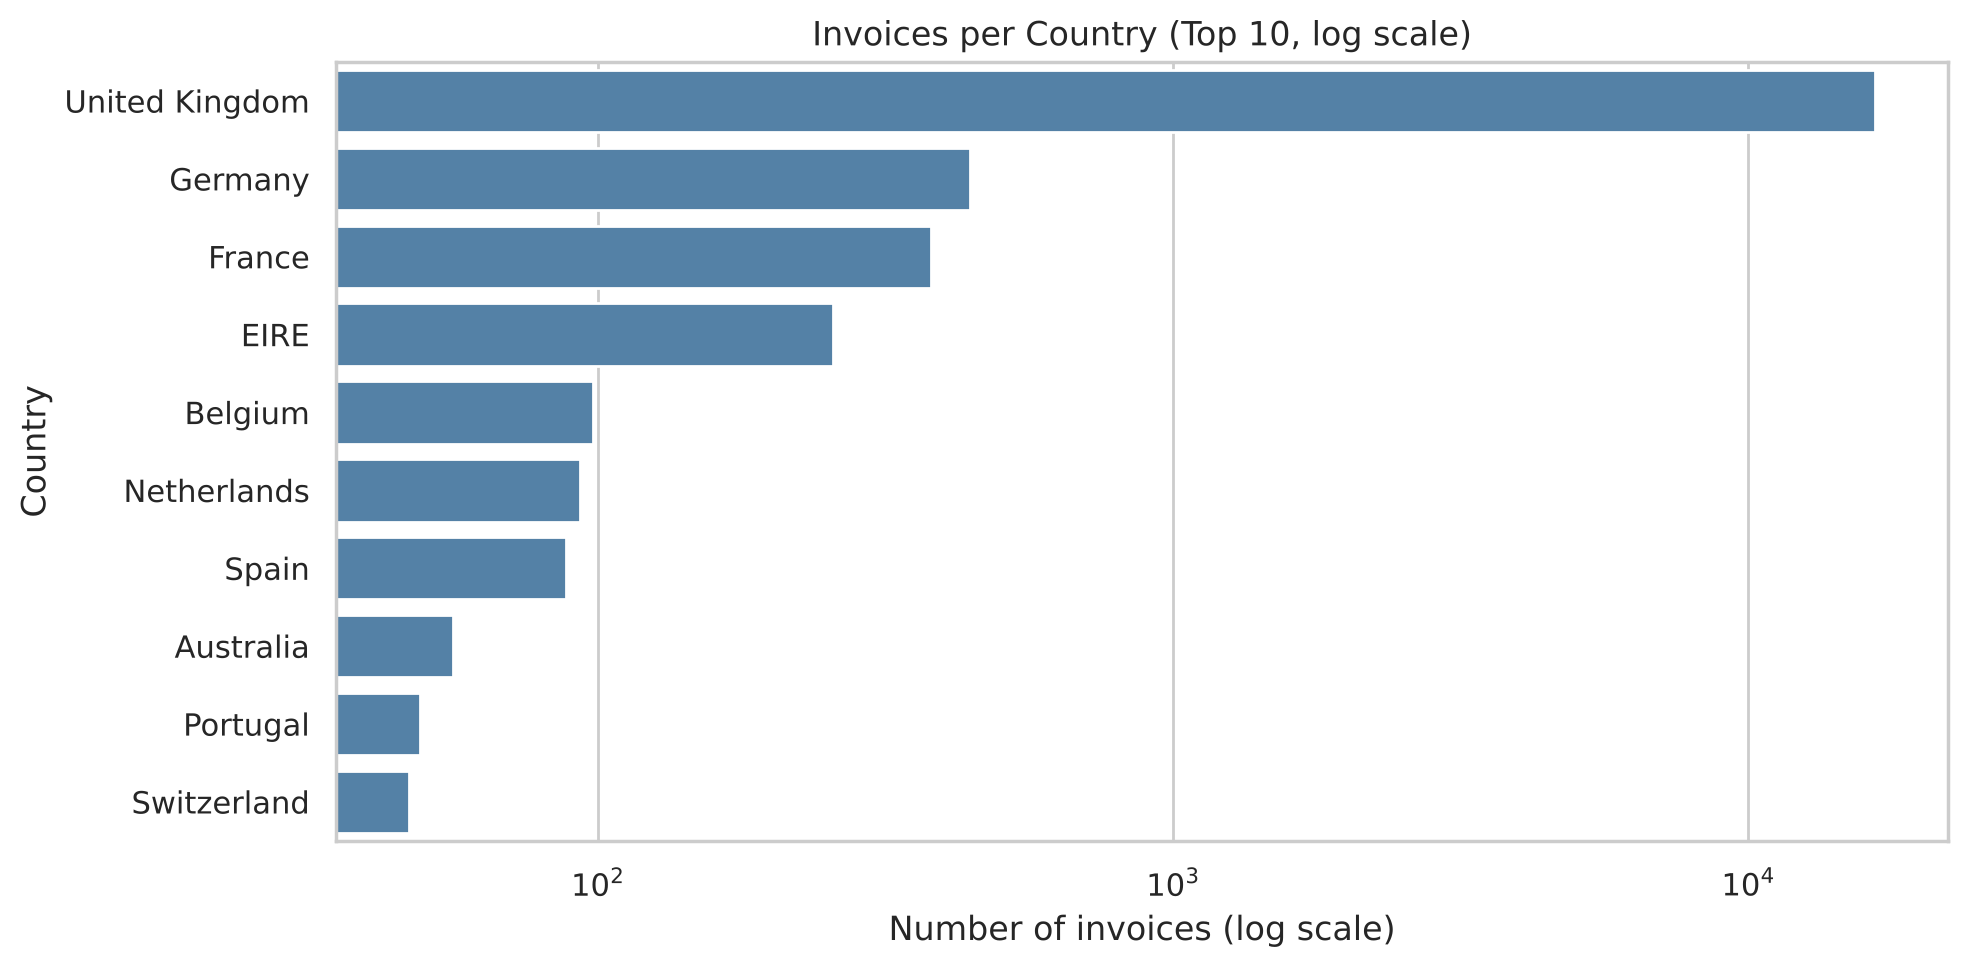

UK share of all cleaned invoices: 90.1%


In [8]:
# Invoices per country (top 10) – justifies focusing on the UK
country_invoices = df.groupby("Country")["InvoiceNo"].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=country_invoices.values, y=country_invoices.index, color="steelblue")
plt.xscale("log")  # log scale so the smaller countries are still visible next to the UK
plt.title("Invoices per Country (Top 10, log scale)")
plt.xlabel("Number of invoices (log scale)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

uk_share = country_invoices.iloc[0] / df["InvoiceNo"].nunique()
print(f"UK share of all cleaned invoices: {uk_share:.1%}")

In [9]:
# Keep UK transactions and draw a reproducible sample of invoices
uk = df[df["Country"] == "United Kingdom"].copy()
invoice_ids = uk["InvoiceNo"].drop_duplicates()
sample_size = min(5000, len(invoice_ids))
selected_invoices = invoice_ids.sample(n=sample_size, random_state=42)
uk = uk[uk["InvoiceNo"].isin(selected_invoices)]

print("Total UK invoices available:", len(invoice_ids))
print("UK invoices selected:", uk["InvoiceNo"].nunique())
print("Product lines in the sample:", len(uk))

Total UK invoices available: 16579
UK invoices selected: 5000
Product lines in the sample: 106183


### 1.6 Build the transaction-item matrix
Apriori and FP-Growth in `mlxtend` expect a one-hot (boolean) DataFrame: one row per invoice, one column per product,
`True` if the product appears on the invoice. Quantities are ignored because association rules only care whether an item
was bought, not how many.

In [10]:
# One row per invoice, one column per product, True if the product was bought on that invoice
basket = (
    uk.groupby(["InvoiceNo", "Description"])["Quantity"]
    .sum()
    .unstack(fill_value=0)
    .gt(0)
)

density = basket.values.mean()
print("Transaction-item matrix shape:", basket.shape)
print(f"Matrix density: {density:.4%} of cells are True (very sparse)")
basket.iloc[:5, :6]

Transaction-item matrix shape: (5000, 3502)
Matrix density: 0.5979% of cells are True (very sparse)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,
536365,False,False,False,False,False,False
536368,False,False,False,False,False,False
536374,False,False,False,False,False,False
536381,False,False,False,False,False,False
536382,False,False,False,False,False,False


### 1.7 Exploratory visualizations

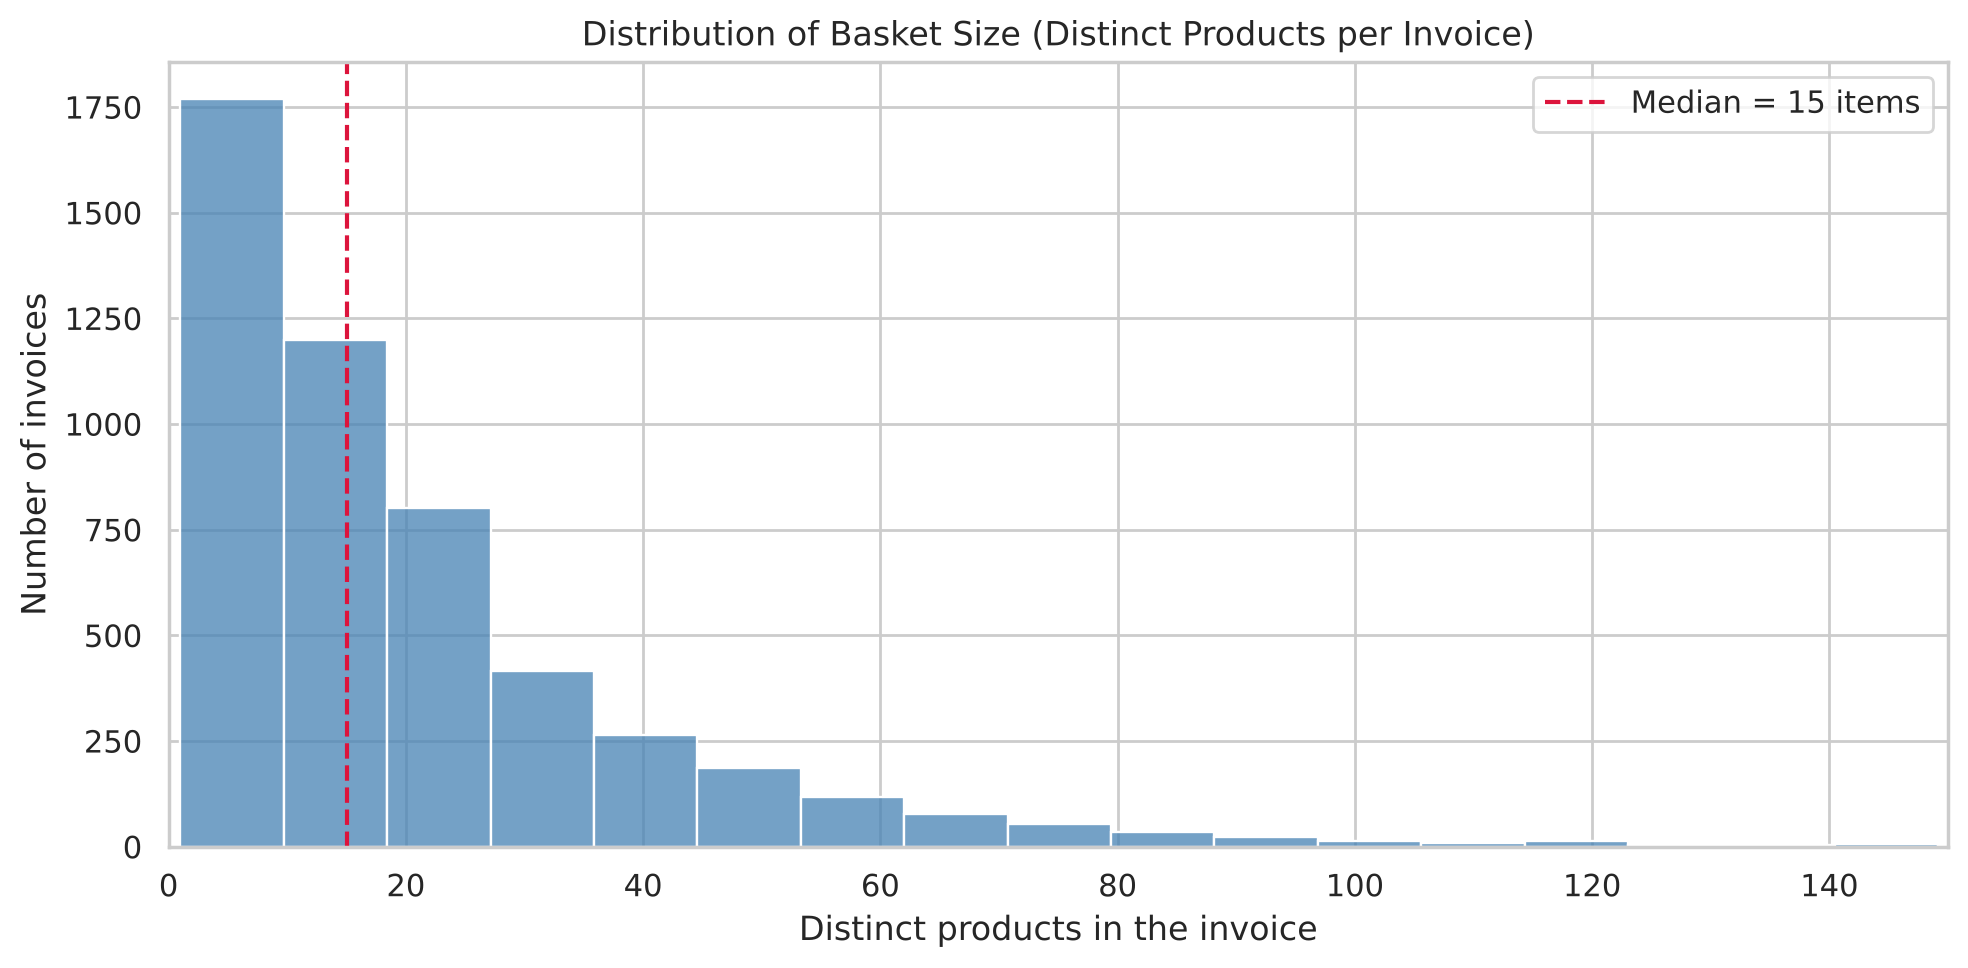

,Basket size
count,5000.0
mean,20.9
std,24.1
min,1.0
25%,6.0
50%,15.0
75%,27.0
max,524.0


In [11]:
# Distribution of basket size (distinct products per invoice)
basket_sizes = basket.sum(axis=1)

plt.figure(figsize=(10, 5))
sns.histplot(basket_sizes, bins=60, color="steelblue")
plt.axvline(basket_sizes.median(), color="crimson", linestyle="--",
            label=f"Median = {basket_sizes.median():.0f} items")
plt.title("Distribution of Basket Size (Distinct Products per Invoice)")
plt.xlabel("Distinct products in the invoice")
plt.ylabel("Number of invoices")
plt.xlim(0, 150)
plt.legend()
plt.tight_layout()
plt.show()

basket_sizes.describe().round(1).to_frame("Basket size")

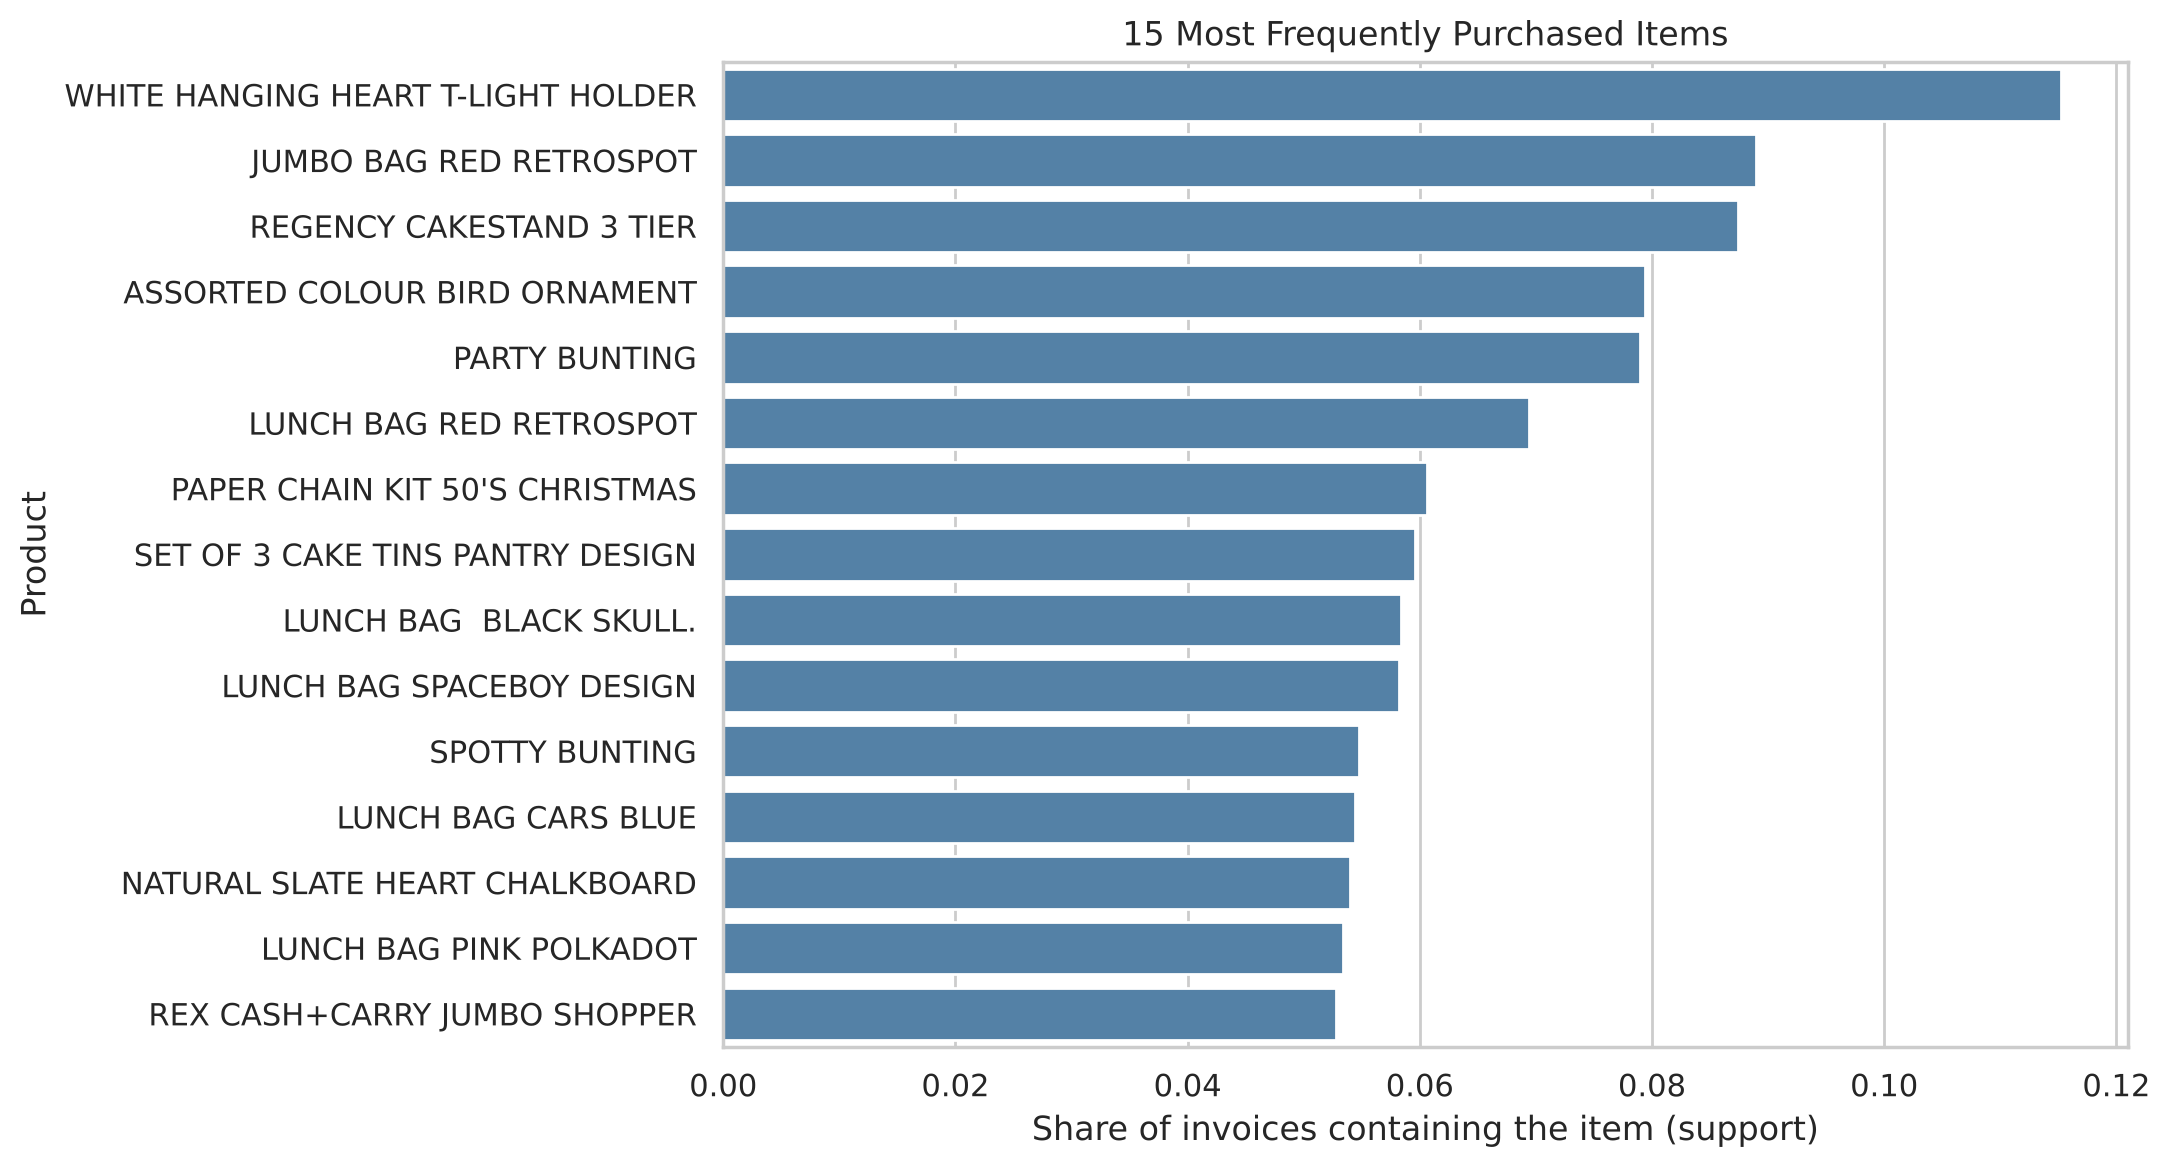

In [12]:
# 15 most frequently purchased items, shown as the share of invoices containing them (= item support)
item_support = basket.mean().sort_values(ascending=False)
top_items = item_support.head(15)

plt.figure(figsize=(11, 6))
sns.barplot(x=top_items.values, y=top_items.index, color="steelblue")
plt.title("15 Most Frequently Purchased Items")
plt.xlabel("Share of invoices containing the item (support)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

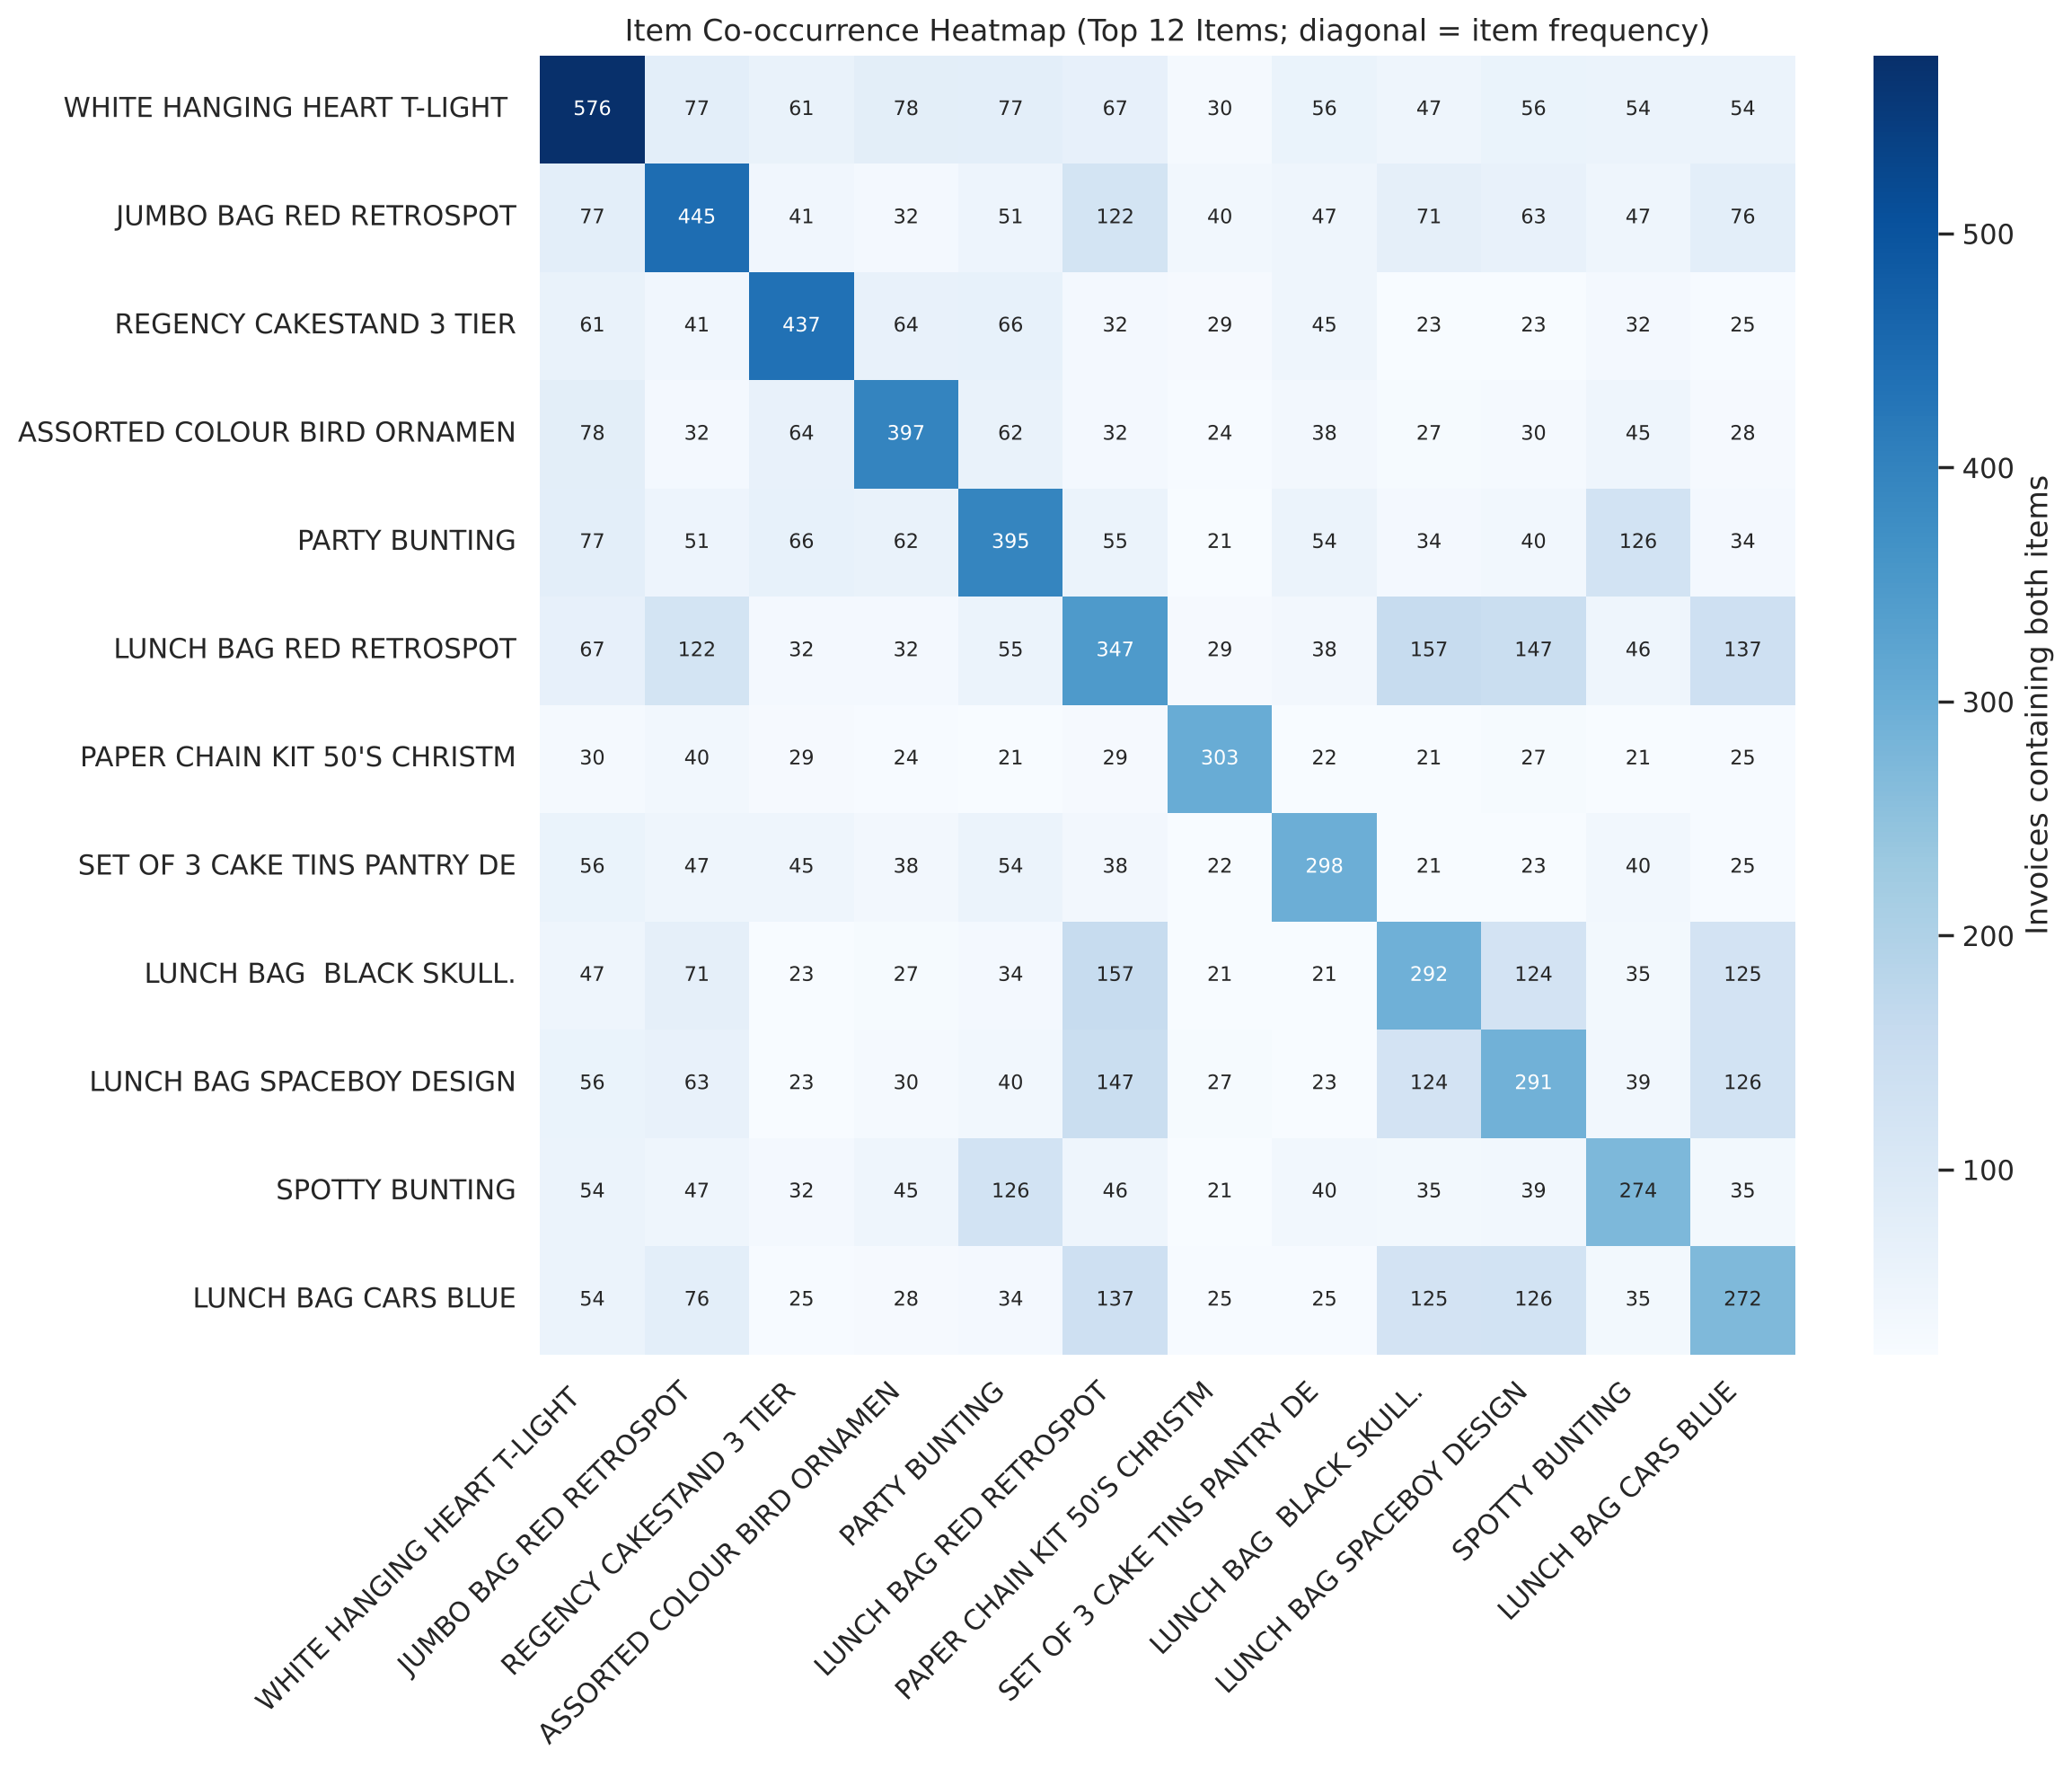

In [13]:
# Co-occurrence heatmap among the 12 most frequent items
selected_items = top_items.head(12).index
onehot = basket[selected_items].astype(int)
cooccurrence = onehot.T.dot(onehot)        # cell (i, j) = invoices containing both item i and item j

short = [name[:28] for name in selected_items]   # shorten long product names for readable axes
cooc_plot = cooccurrence.copy()
cooc_plot.index, cooc_plot.columns = short, short

plt.figure(figsize=(12, 10))
sns.heatmap(cooc_plot, cmap="Blues", annot=True, fmt="d", annot_kws={"size": 8},
            cbar_kws={"label": "Invoices containing both items"})
plt.title("Item Co-occurrence Heatmap (Top 12 Items; diagonal = item frequency)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Exploration insights**

- **Sparsity.** The median invoice contains **15 distinct products** (mean 21, max 524) out of about 3,500 possible
  items, so under 0.6% of the matrix is `True`. Supports will therefore be small, and the support threshold has to be
  set low.
- **Most popular items.** The *White Hanging Heart T-Light Holder* is the top seller, appearing in about **11.5%** of
  invoices. It is followed by the *Jumbo Bag Red Retrospot*, *Regency Cakestand 3 Tier*, *Assorted Colour Bird
  Ornament* and *Party Bunting* (each around 8–9%). The top 15 are dominated by home décor, gift bags and lunch bags.
- **Co-occurrence.** The heatmap's off-diagonal cells show the **lunch-bag family** buying pattern most clearly.
  *Lunch Bag Red Retrospot* appears with *Lunch Bag Black Skull* in **157** invoices, with *Spaceboy Design* in **147**
  and with *Cars Blue* in **137**. Customers (many of them wholesalers) buy several designs of the same product line
  together, which is the pattern the association rules should pick up.

## Step 2: Frequent Itemset Mining Using Apriori

### Choosing the support threshold
The data is very sparse (median basket ≈ 15 products out of ~3,400). Even the most popular item appears in only about
11% of invoices, so a high threshold such as 0.05 would leave almost nothing but single items. The sweep below counts
frequent itemsets at several thresholds to pick a sensible value.

In [14]:
# Count frequent itemsets at several candidate thresholds (FP-Growth is used here because it is quick)
sweep = []
for s in [0.05, 0.04, 0.03, 0.025, 0.02, 0.015, 0.01]:
    fi = fpgrowth(basket, min_support=s, use_colnames=True, max_len=3)
    sizes = fi["itemsets"].apply(len)
    sweep.append({"min_support": s, "itemsets": len(fi),
                  "1-item": (sizes == 1).sum(), "2-item": (sizes == 2).sum(), "3-item": (sizes == 3).sum()})
pd.DataFrame(sweep)

,min_support,itemsets,1-item,2-item,3-item
0,0.050,17,17,0,0
1,0.040,44,44,0,0
2,0.030,96,92,4,0
3,0.025,160,144,16,0
4,0.020,254,215,39,0
5,0.015,466,357,100,9
6,0.010,1046,621,339,86


**Chosen threshold: `min_support = 0.015` (an itemset must appear in at least 75 of the 5,000 invoices).**

- At 0.05 and 0.04, **only single items** are frequent, so no rules are possible.
- At 0.02, pairs appear (39) but **no 3-item itemsets** do.
- **0.015 is the highest threshold at which 3-item itemsets appear** (9 of them, plus 100 pairs). It still requires
  75 occurrences, which filters out chance combinations.
- 0.01 more than doubles the itemsets (1,046) and adds many weak, rarely bought combinations, and Apriori gets much
  slower (see Step 3).

`max_len = 3` caps itemsets at three products. Longer itemsets are extremely rare at this support, and the cap keeps
Apriori's candidate generation bounded.

In [15]:
# Settings shared by both algorithms
min_support = 0.015  # itemset must appear in at least 1.5% of invoices (= 75 of 5,000)
max_len = 3          # itemsets of up to 3 products
n_runs = 5           # repeat timing runs and take the median for a fair comparison

def timed_mining(algorithm):
    """Run a mining function n_runs times; return the itemsets and the median runtime in seconds."""
    times = []
    for _ in range(n_runs):
        start = time.perf_counter()
        result = algorithm(basket, min_support=min_support, use_colnames=True, max_len=max_len)
        times.append(time.perf_counter() - start)
    return result, pd.Series(times).median(), times

apriori_itemsets, apriori_time, apriori_times = timed_mining(apriori)
apriori_itemsets["length"] = apriori_itemsets["itemsets"].apply(len)
apriori_itemsets = apriori_itemsets.sort_values("support", ascending=False).reset_index(drop=True)

print(f"Apriori median runtime over {n_runs} runs: {apriori_time:.3f} seconds")
print("Number of frequent itemsets:", len(apriori_itemsets))
print(apriori_itemsets["length"].value_counts().sort_index().rename("itemsets by size").to_string())
apriori_itemsets.head(15)

Apriori median runtime over 5 runs: 3.718 seconds
Number of frequent itemsets: 466
length
1    357
2    100
3      9


,support,itemsets,length
0,0.1152,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
1,0.0890,frozenset({JUMBO BAG RED RETROSPOT}),1
2,0.0874,frozenset({REGENCY CAKESTAND 3 TIER}),1
3,0.0794,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
4,0.0790,frozenset({PARTY BUNTING}),1
5,0.0694,frozenset({LUNCH BAG RED RETROSPOT}),1
6,0.0606,frozenset({PAPER CHAIN KIT 50'S CHRISTMAS}),1
7,0.0596,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
8,0.0584,frozenset({LUNCH BAG BLACK SKULL.}),1
9,0.0582,frozenset({LUNCH BAG SPACEBOY DESIGN}),1


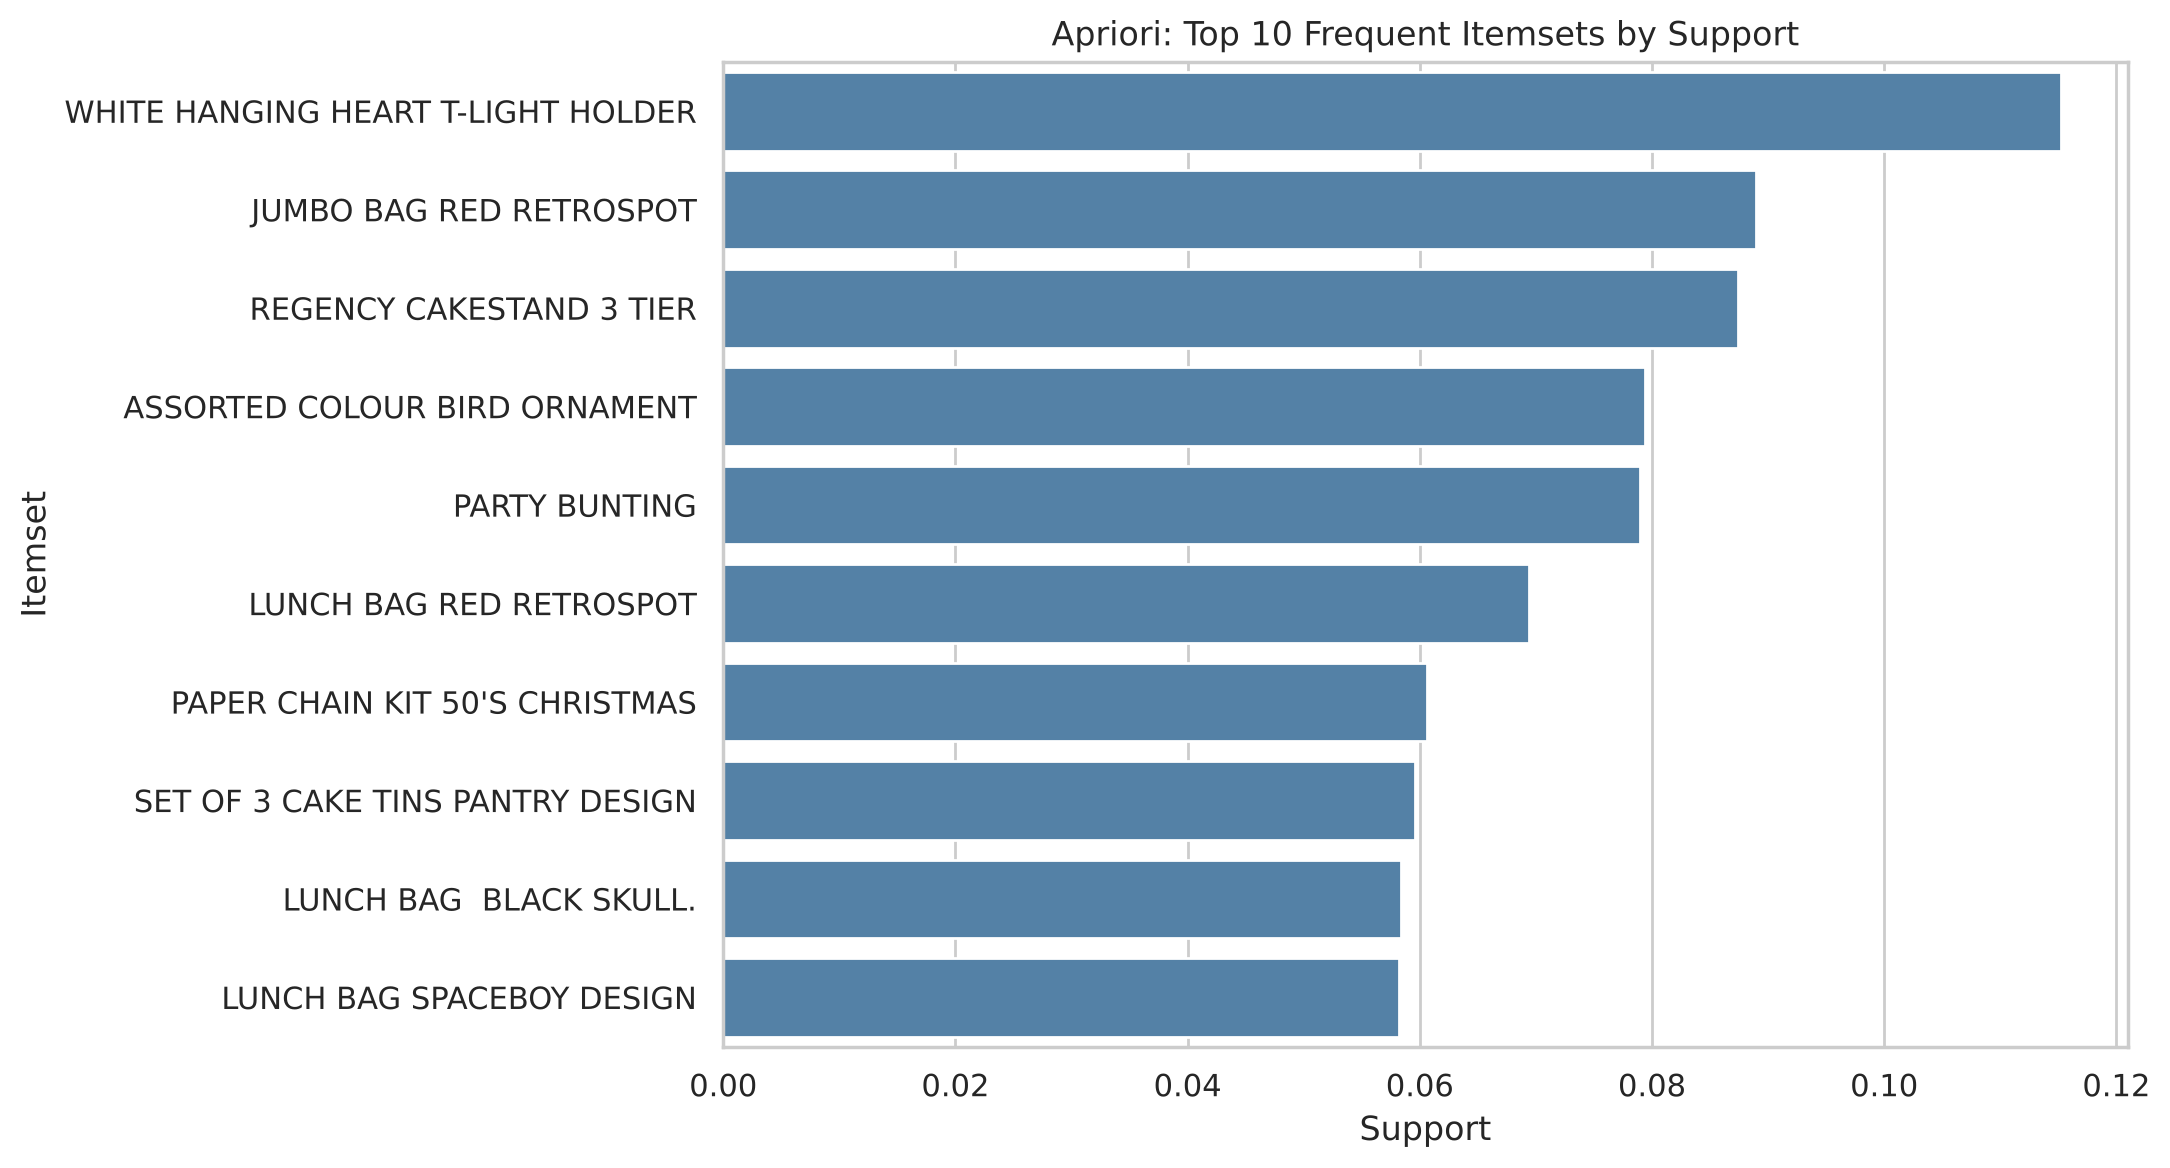

In [16]:
# Helper: turn a frozenset of items into a readable label
def label(itemset, width=40):
    return " + ".join(name[:width] for name in sorted(itemset))

# Top 10 Apriori itemsets overall (dominated by single items)
apriori_top = apriori_itemsets.head(10).copy()
apriori_top["itemset"] = apriori_top["itemsets"].apply(label)

plt.figure(figsize=(11, 6))
sns.barplot(data=apriori_top, x="support", y="itemset", color="steelblue")
plt.title("Apriori: Top 10 Frequent Itemsets by Support")
plt.xlabel("Support")
plt.ylabel("Itemset")
plt.tight_layout()
plt.show()

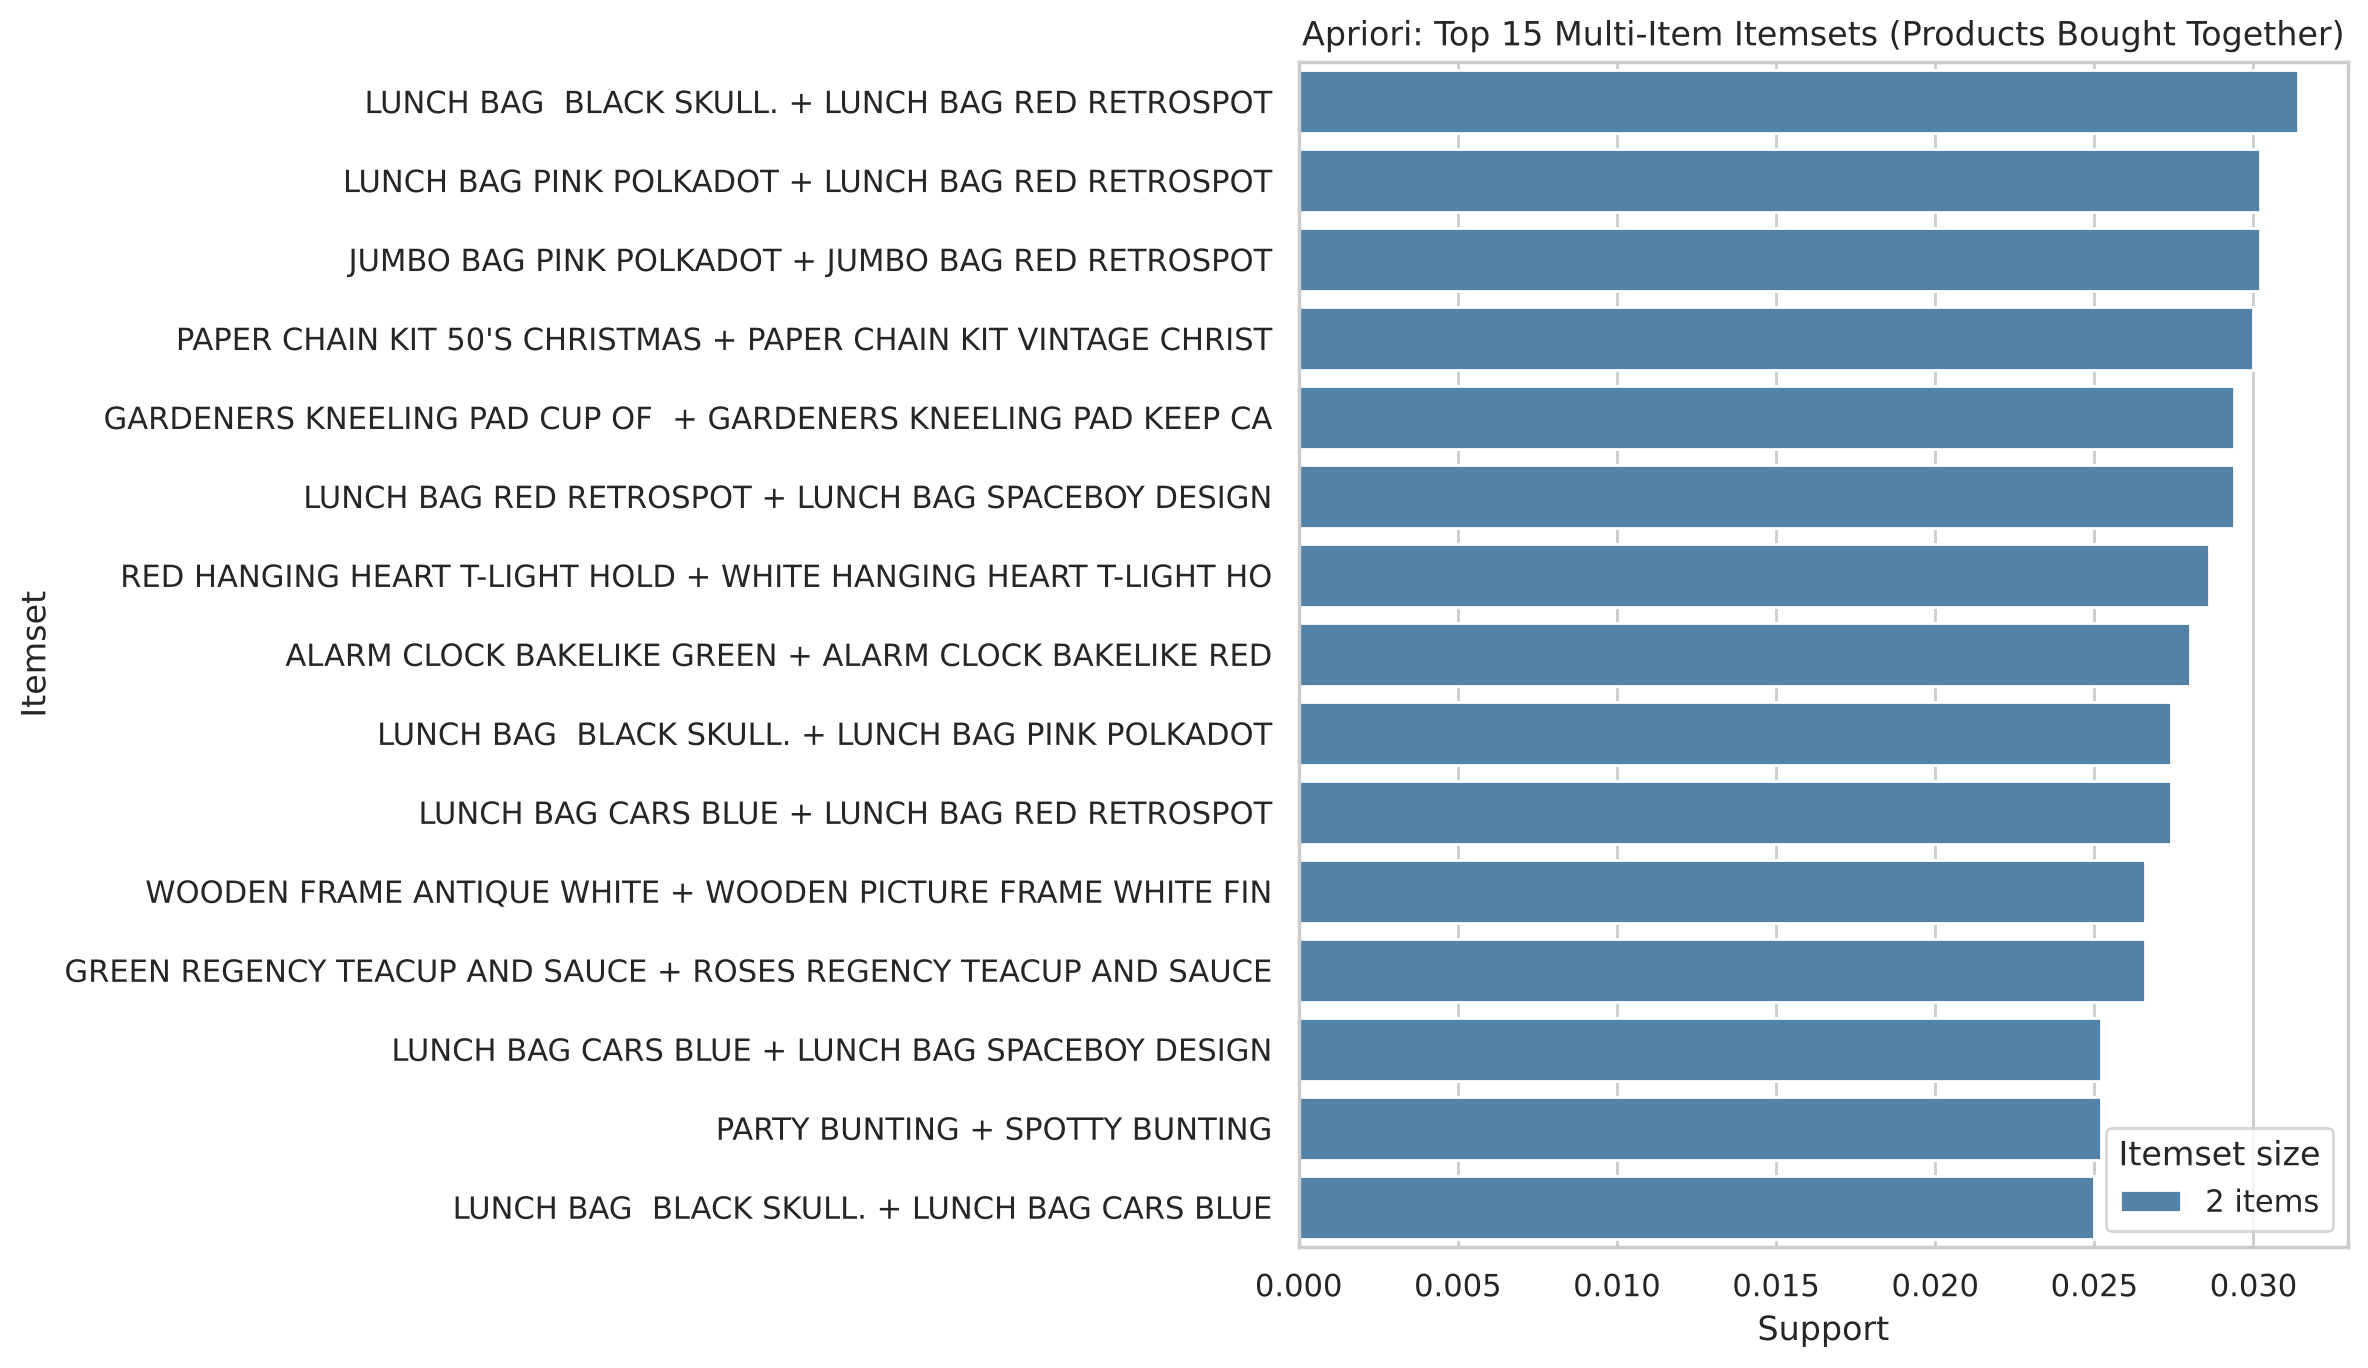

In [17]:
# Top 15 multi-item (2- and 3-item) itemsets – these show which products are bought together
apriori_multi = apriori_itemsets[apriori_itemsets["length"] >= 2].head(15).copy()
apriori_multi["itemset"] = apriori_multi["itemsets"].apply(lambda s: label(s, 30))
apriori_multi["size"] = apriori_multi["length"].astype(str) + " items"

plt.figure(figsize=(12, 7))
sns.barplot(data=apriori_multi, x="support", y="itemset", hue="size", dodge=False,
            palette={"2 items": "steelblue", "3 items": "darkorange"})
plt.title("Apriori: Top 15 Multi-Item Itemsets (Products Bought Together)")
plt.xlabel("Support")
plt.ylabel("Itemset")
plt.legend(title="Itemset size")
plt.tight_layout()
plt.show()

**Apriori insights**

- Apriori finds **466 frequent itemsets**: 357 single items, 100 pairs and 9 triples.
- The overall top 10 contains only single items, because a single item is always at least as frequent as any set
  containing it. That is why the second chart shows only the multi-item itemsets.
- The most common pairs are **variants of the same product line**:
  - *Lunch Bag Red Retrospot + Lunch Bag Black Skull* (support 3.1%)
  - *Lunch Bag Red Retrospot + Lunch Bag Pink Polkadot* (3.0%)
  - *Jumbo Bag Pink Polkadot + Jumbo Bag Red Retrospot* (3.0%)
  - The two *Paper Chain Kit* Christmas designs (3.0%)
  - The two *Gardeners Kneeling Pad* designs (2.9%)
- All 9 three-item itemsets are colour or design sets (for example, the **Green / Pink / Roses Regency Teacup and
  Saucer** trio). This suggests customers stock a whole collection rather than a single variant.

## Step 3: Frequent Itemset Mining Using FP-Growth
FP-Growth is run on the same matrix with the **same** `min_support = 0.015` and `max_len = 3`, and timed the same way.

In [18]:
# FP-Growth with identical settings
fpgrowth_itemsets, fpgrowth_time, fpgrowth_times = timed_mining(fpgrowth)
fpgrowth_itemsets["length"] = fpgrowth_itemsets["itemsets"].apply(len)
fpgrowth_itemsets = fpgrowth_itemsets.sort_values("support", ascending=False).reset_index(drop=True)

print(f"FP-Growth median runtime over {n_runs} runs: {fpgrowth_time:.3f} seconds")
print("Number of frequent itemsets:", len(fpgrowth_itemsets))
print(fpgrowth_itemsets["length"].value_counts().sort_index().rename("itemsets by size").to_string())
fpgrowth_itemsets.head(15)

FP-Growth median runtime over 5 runs: 0.233 seconds
Number of frequent itemsets: 466
length
1    357
2    100
3      9


,support,itemsets,length
0,0.1152,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
1,0.0890,frozenset({JUMBO BAG RED RETROSPOT}),1
2,0.0874,frozenset({REGENCY CAKESTAND 3 TIER}),1
3,0.0794,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
4,0.0790,frozenset({PARTY BUNTING}),1
5,0.0694,frozenset({LUNCH BAG RED RETROSPOT}),1
6,0.0606,frozenset({PAPER CHAIN KIT 50'S CHRISTMAS}),1
7,0.0596,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
8,0.0584,frozenset({LUNCH BAG BLACK SKULL.}),1
9,0.0582,frozenset({LUNCH BAG SPACEBOY DESIGN}),1


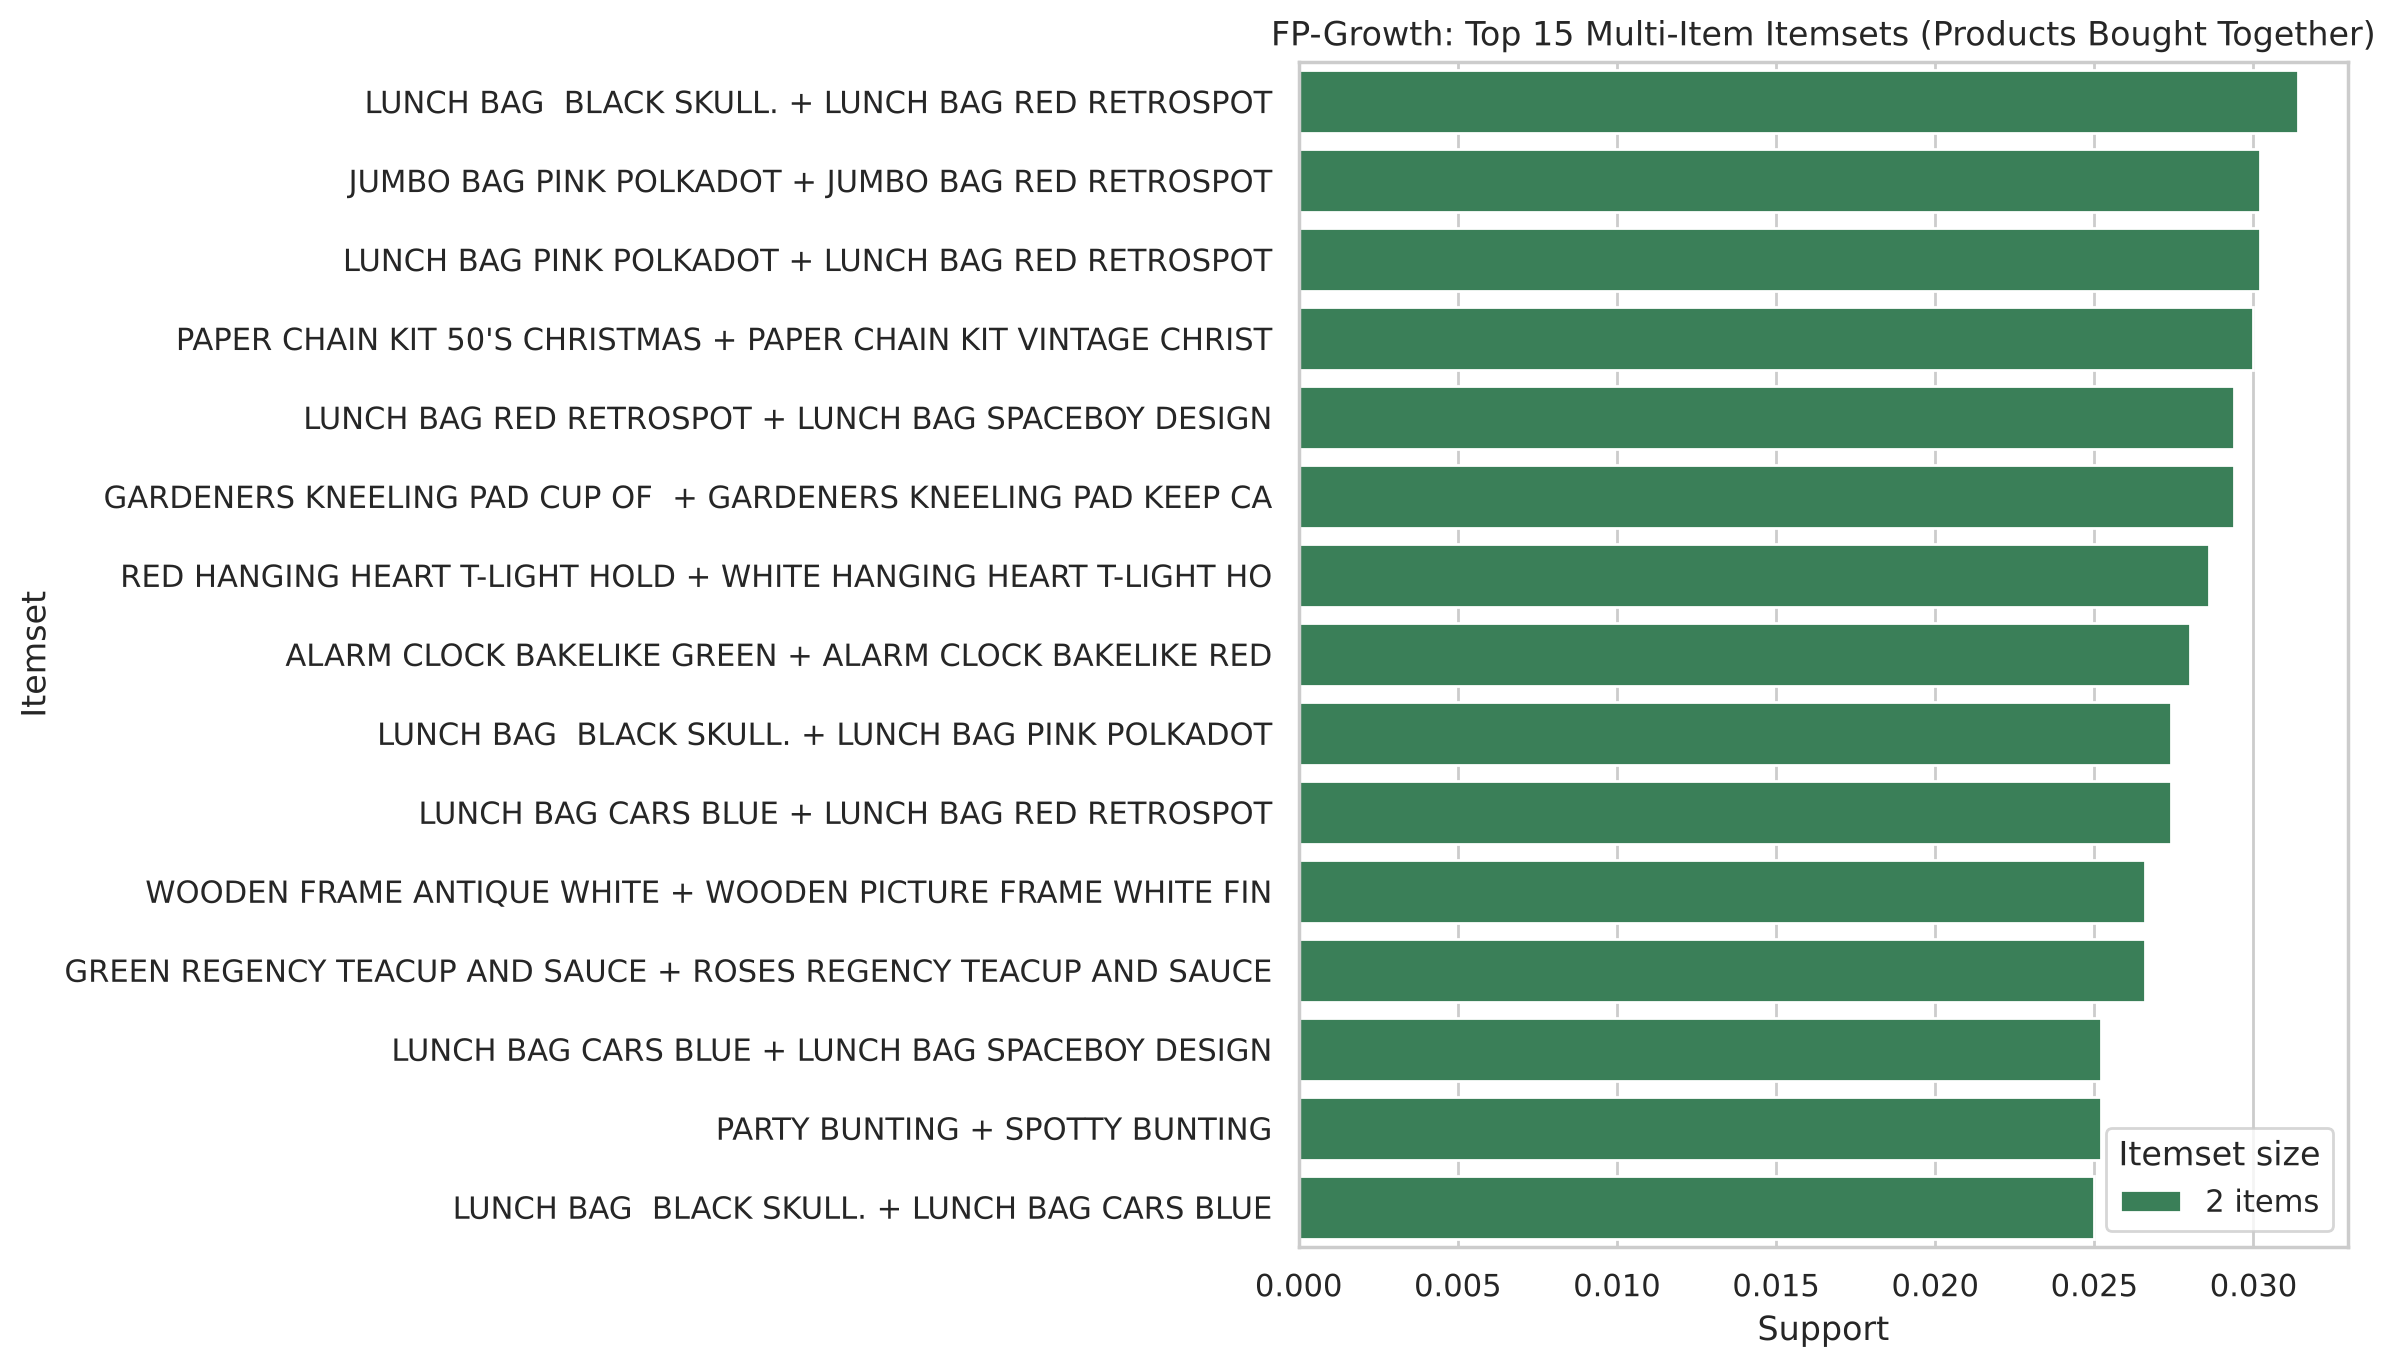

In [19]:
# Top 15 multi-item FP-Growth itemsets
fp_multi = fpgrowth_itemsets[fpgrowth_itemsets["length"] >= 2].head(15).copy()
fp_multi["itemset"] = fp_multi["itemsets"].apply(lambda s: label(s, 30))
fp_multi["size"] = fp_multi["length"].astype(str) + " items"

plt.figure(figsize=(12, 7))
sns.barplot(data=fp_multi, x="support", y="itemset", hue="size", dodge=False,
            palette={"2 items": "seagreen", "3 items": "darkorange"})
plt.title("FP-Growth: Top 15 Multi-Item Itemsets (Products Bought Together)")
plt.xlabel("Support")
plt.ylabel("Itemset")
plt.legend(title="Itemset size")
plt.tight_layout()
plt.show()

### 3.1 Comparing FP-Growth with Apriori
Check that the two algorithms find **exactly the same itemsets with the same support** (not just the same count),
then compare their runtimes.

In [20]:
# Compare outputs itemset by itemset
a = dict(zip(apriori_itemsets["itemsets"], apriori_itemsets["support"]))
f = dict(zip(fpgrowth_itemsets["itemsets"], fpgrowth_itemsets["support"]))

only_apriori = set(a) - set(f)
only_fp = set(f) - set(a)
max_support_diff = max(abs(a[k] - f[k]) for k in set(a) & set(f))

print("Itemsets found only by Apriori:  ", len(only_apriori))
print("Itemsets found only by FP-Growth:", len(only_fp))
print("Largest support difference on shared itemsets:", max_support_diff)
print("Identical output:", not only_apriori and not only_fp and max_support_diff < 1e-12)

comparison = pd.DataFrame({
    "Algorithm": ["Apriori", "FP-Growth"],
    "Median runtime (s)": [apriori_time, fpgrowth_time],
    "Min runtime (s)": [min(apriori_times), min(fpgrowth_times)],
    "Frequent itemsets": [len(apriori_itemsets), len(fpgrowth_itemsets)],
}).round(3)
comparison

Itemsets found only by Apriori:   0
Itemsets found only by FP-Growth: 0
Largest support difference on shared itemsets: 0.0
Identical output: True


,Algorithm,Median runtime (s),Min runtime (s),Frequent itemsets
0,Apriori,3.718,3.674,466
1,FP-Growth,0.233,0.194,466


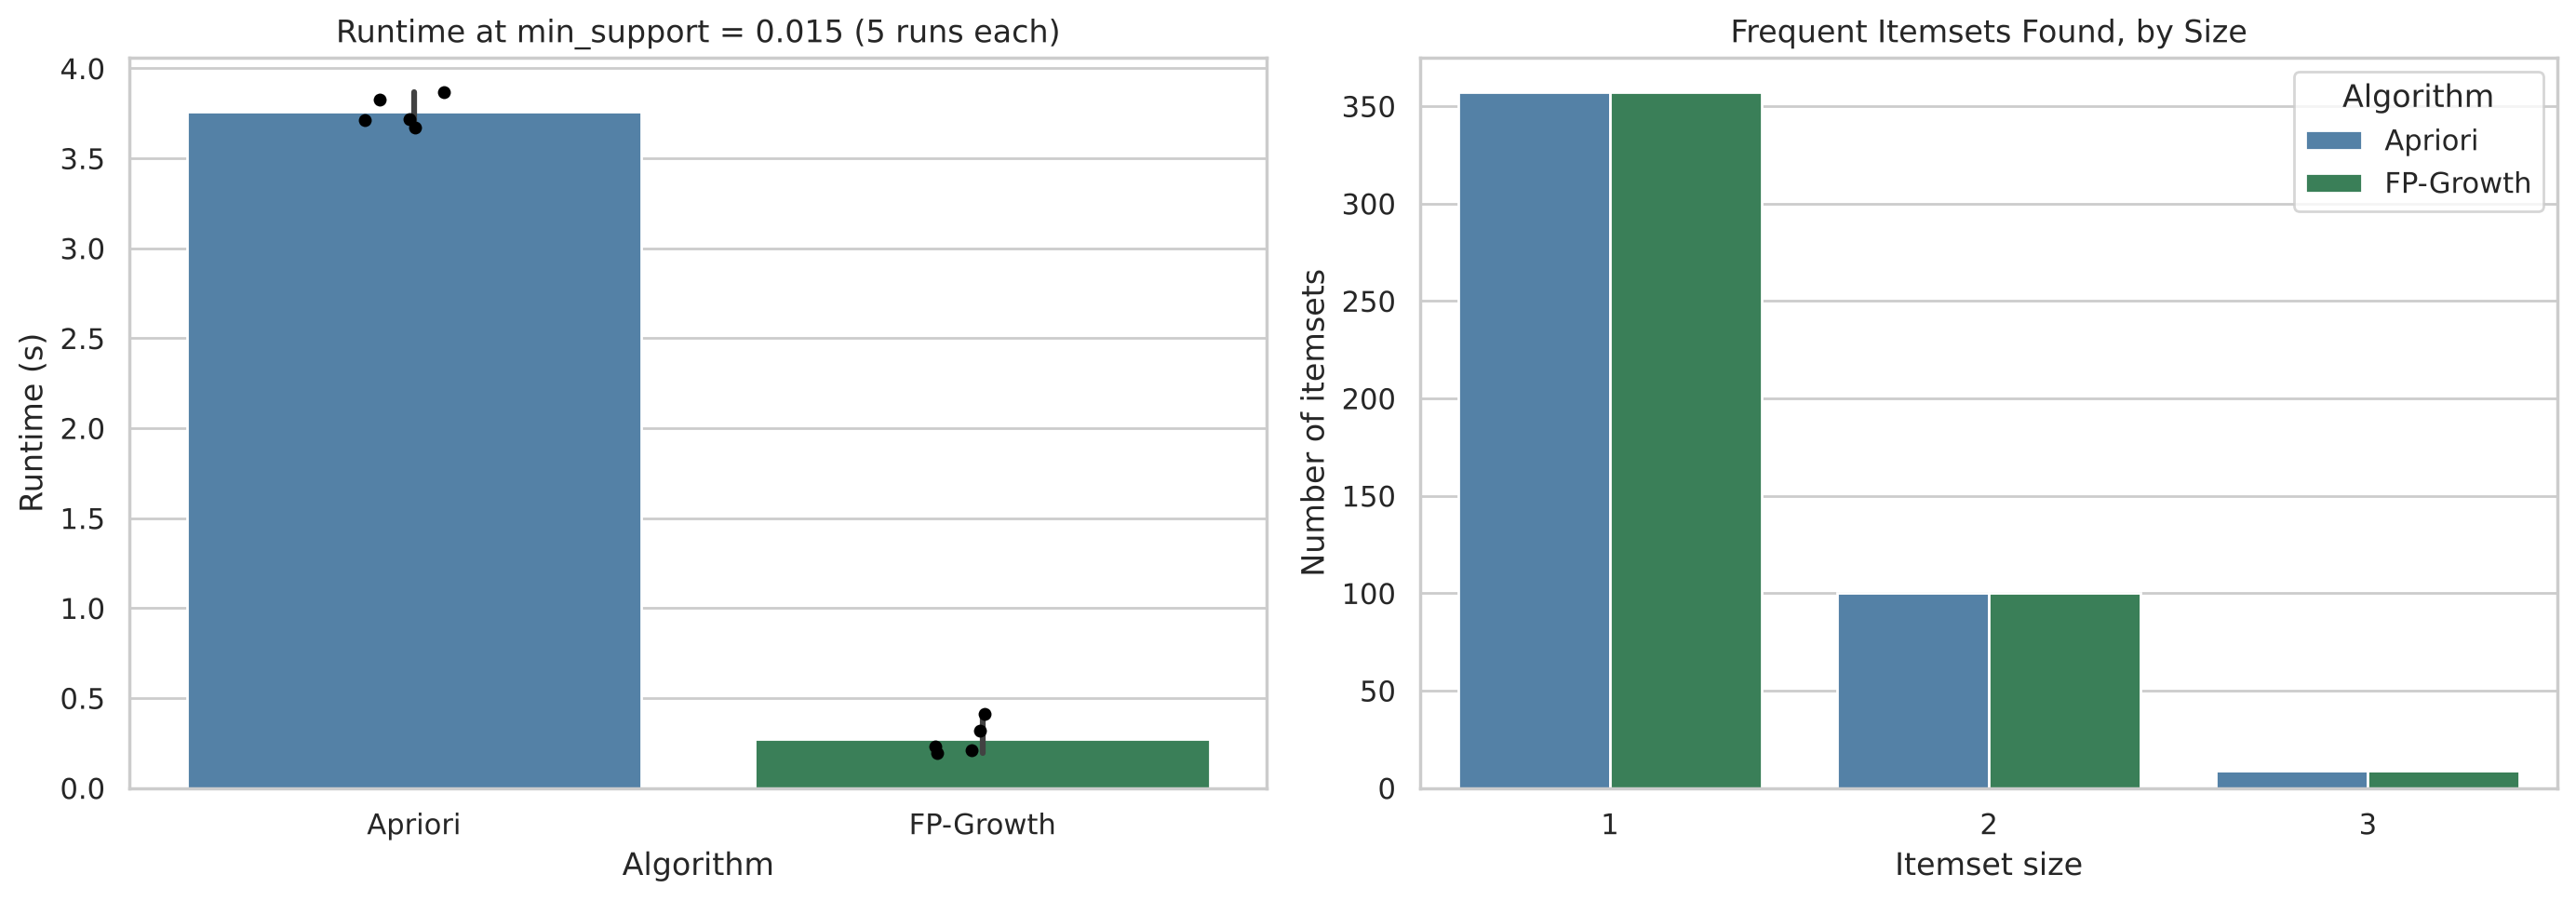

In [21]:
# Visual comparison: runtime (all timing runs) and itemset counts by size
timing_df = pd.DataFrame({
    "Algorithm": ["Apriori"] * n_runs + ["FP-Growth"] * n_runs,
    "Runtime (s)": apriori_times + fpgrowth_times,
})
size_counts = pd.concat([
    apriori_itemsets["length"].value_counts().rename("count").to_frame().assign(Algorithm="Apriori"),
    fpgrowth_itemsets["length"].value_counts().rename("count").to_frame().assign(Algorithm="FP-Growth"),
]).rename_axis("Itemset size").reset_index()

palette = {"Apriori": "steelblue", "FP-Growth": "seagreen"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=timing_df, x="Algorithm", y="Runtime (s)", hue="Algorithm", palette=palette,
            errorbar=("pi", 100), ax=axes[0])
sns.stripplot(data=timing_df, x="Algorithm", y="Runtime (s)", color="black", size=5, ax=axes[0])
axes[0].set_title(f"Runtime at min_support = {min_support} ({n_runs} runs each)")

sns.barplot(data=size_counts, x="Itemset size", y="count", hue="Algorithm", palette=palette, ax=axes[1])
axes[1].set_title("Frequent Itemsets Found, by Size")
axes[1].set_ylabel("Number of itemsets")

plt.tight_layout()
plt.show()

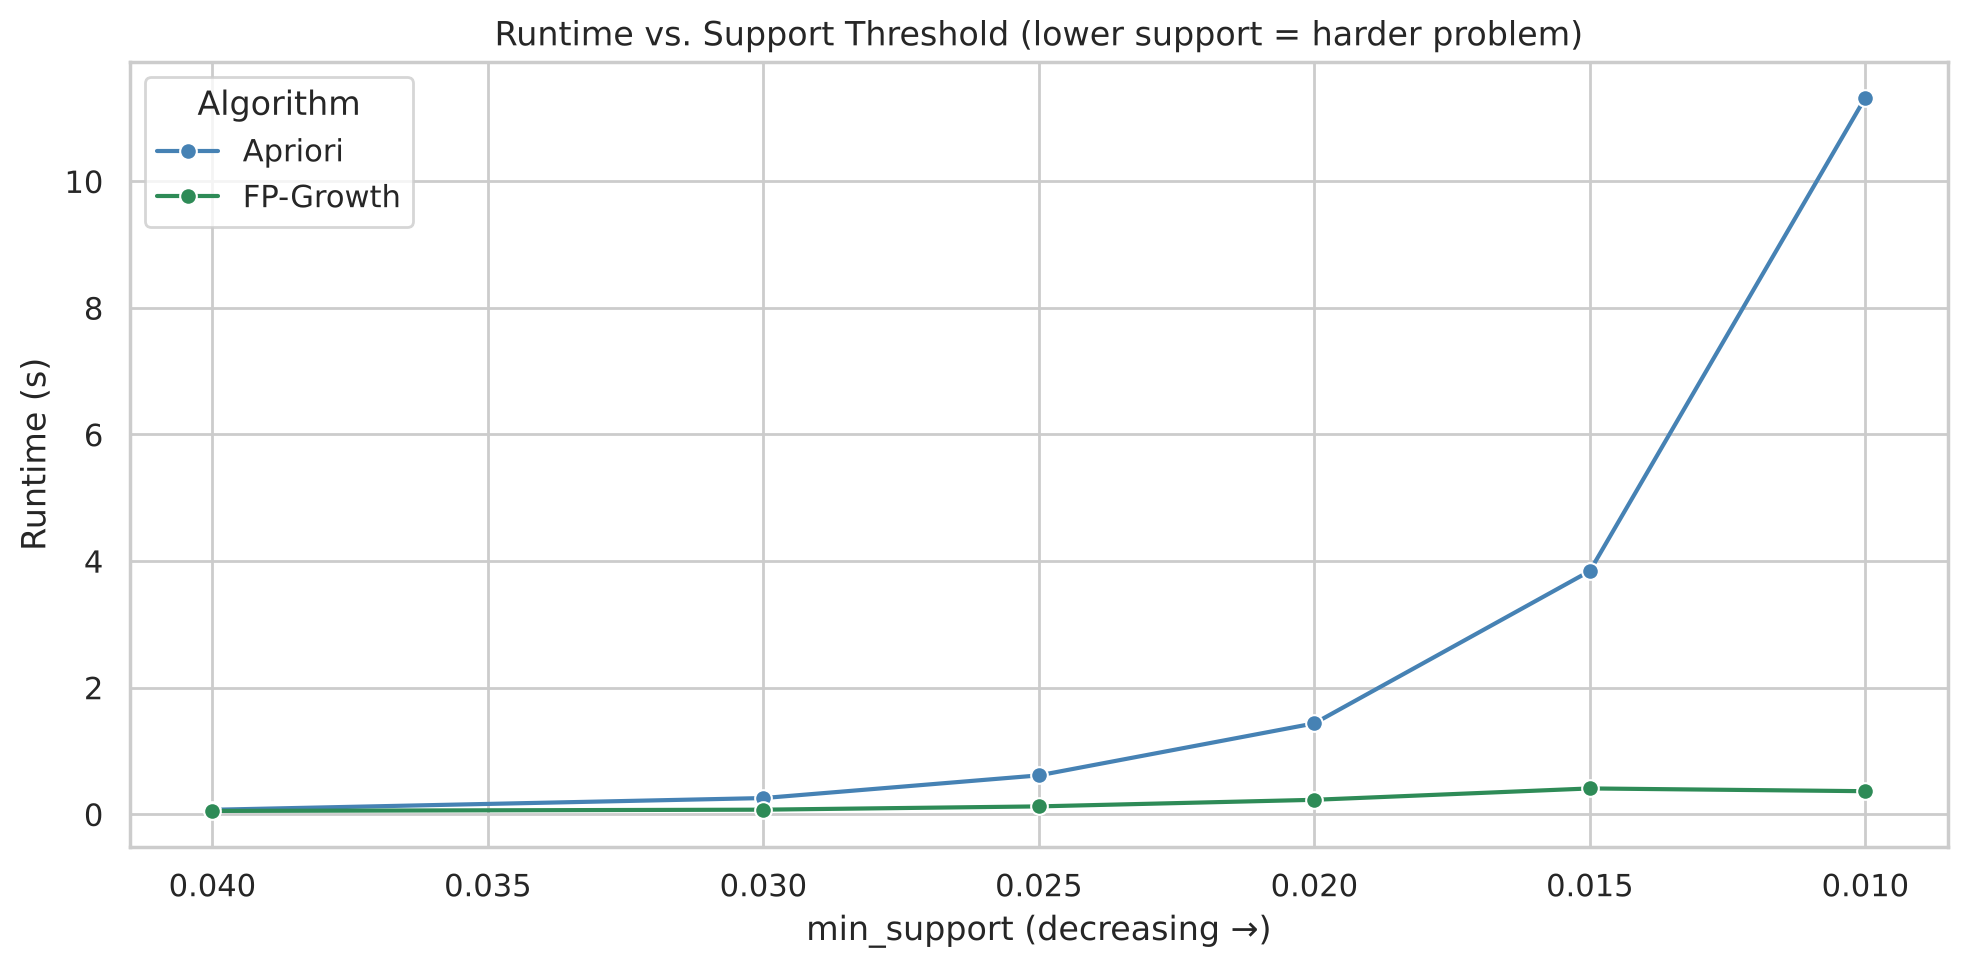

Algorithm,Apriori,FP-Growth
min_support,,
0.040,0.071,0.052
0.030,0.256,0.072
0.025,0.614,0.124
0.020,1.436,0.228
0.015,3.843,0.408
0.010,11.322,0.364


In [22]:
# Efficiency across support thresholds: lower support = more candidates for Apriori to generate and count
scaling = []
for s in [0.04, 0.03, 0.025, 0.02, 0.015, 0.01]:
    for name, algorithm in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
        start = time.perf_counter()
        n = len(algorithm(basket, min_support=s, use_colnames=True, max_len=max_len))
        scaling.append({"min_support": s, "Algorithm": name,
                        "Runtime (s)": time.perf_counter() - start, "Itemsets": n})
scaling = pd.DataFrame(scaling)

plt.figure(figsize=(10, 5))
sns.lineplot(data=scaling, x="min_support", y="Runtime (s)", hue="Algorithm", marker="o", palette=palette)
plt.gca().invert_xaxis()   # read left-to-right as the threshold gets stricter -> looser
plt.title("Runtime vs. Support Threshold (lower support = harder problem)")
plt.xlabel("min_support (decreasing →)")
plt.tight_layout()
plt.show()

scaling.pivot(index="min_support", columns="Algorithm", values="Runtime (s)").round(3).sort_index(ascending=False)

**FP-Growth vs. Apriori: output and efficiency**

- **Same output.** FP-Growth returns **exactly the same 466 itemsets with identical support values**: no itemset is
  unique to either algorithm and the largest support difference is 0.0. This is expected, because both are *exact*
  algorithms that find every itemset above the threshold. They differ only in *how* they search.
- **Speed.** FP-Growth was about **15× faster** at the chosen threshold (median ≈ 0.25 s vs. ≈ 3.7 s over 5 runs).
- **Scaling.** The runtime sweep shows the gap widening as support decreases:
  - At 0.04 the two are almost equal (≈ 0.07 s vs. 0.06 s).
  - At 0.01 Apriori takes about **11.5 s** while FP-Growth takes about **0.35 s** (≈ 30×).
  - Apriori's runtime grows steeply with the number of candidates, while FP-Growth stays nearly flat.

## Step 4: Generating and Analyzing Association Rules
Rules are generated from both itemset tables with a **minimum confidence of 0.5**: a rule *A → B* is kept only if at
least half of the invoices containing A also contain B. Metrics:
- **Support** – share of all invoices containing both A and B.
- **Confidence** – P(B | A).
- **Lift** – confidence divided by B's overall support. Lift > 1 means A and B appear together more often than chance;
  in this sparse data, lifts of 10+ indicate very strong associations.

In [23]:
# Generate rules from both sets of frequent itemsets
confidence_threshold = 0.5
cols = ["antecedents", "consequents", "support", "confidence", "lift"]

apriori_rules = association_rules(apriori_itemsets, metric="confidence", min_threshold=confidence_threshold)
fp_rules = association_rules(fpgrowth_itemsets, metric="confidence", min_threshold=confidence_threshold)

# Sort strongest first and add readable text labels
for rules in (apriori_rules, fp_rules):
    rules.sort_values(["lift", "confidence"], ascending=False, inplace=True)
    rules.reset_index(drop=True, inplace=True)
    rules["rule"] = rules["antecedents"].apply(lambda s: label(s, 34)) + "  →  " + \
                    rules["consequents"].apply(lambda s: label(s, 34))
    rules["rule_size"] = (rules["antecedents"].apply(len) + rules["consequents"].apply(len)).astype(str) + " items"

# Confirm both algorithms give the same rules
same_rules = (set(zip(apriori_rules["antecedents"], apriori_rules["consequents"]))
              == set(zip(fp_rules["antecedents"], fp_rules["consequents"])))
print("Apriori association rules:  ", len(apriori_rules))
print("FP-Growth association rules:", len(fp_rules))
print("Identical rule sets:", same_rules)
print("Rules with lift > 1:", (apriori_rules["lift"] > 1).sum())

Apriori association rules:   91
FP-Growth association rules: 91
Identical rule sets: True
Rules with lift > 1: 91


In [24]:
# 20 strongest rules (of all rules generated), rounded for readability
apriori_rules[["rule", "support", "confidence", "lift"]].head(20).round(3)

,rule,support,confidence,lift
0,POPPY'S PLAYHOUSE BEDROOM → POPPY'S PLAYHOUSE KITCHEN,0.016,0.832,39.225
1,POPPY'S PLAYHOUSE KITCHEN → POPPY'S PLAYHOUSE BEDROOM,0.016,0.745,39.225
2,WOODEN STAR CHRISTMAS SCANDINAVIAN → WOODEN HEART CHRISTMAS SCANDINAVIA,0.019,0.752,27.445
3,WOODEN HEART CHRISTMAS SCANDINAVIA → WOODEN STAR CHRISTMAS SCANDINAVIAN,0.019,0.686,27.445
4,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER → PINK R...,0.018,0.692,25.063
5,PINK REGENCY TEACUP AND SAUCER → GREEN REGENCY TEACUP AND SAUCER + ROSES R...,0.018,0.667,25.063
6,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER → GREEN R...,0.018,0.868,24.940
7,GREEN REGENCY TEACUP AND SAUCER → PINK REGENCY TEACUP AND SAUCER + ROSES R...,0.018,0.529,24.940
8,PINK REGENCY TEACUP AND SAUCER → GREEN REGENCY TEACUP AND SAUCER,0.022,0.812,23.322
9,GREEN REGENCY TEACUP AND SAUCER → PINK REGENCY TEACUP AND SAUCER,0.022,0.644,23.322


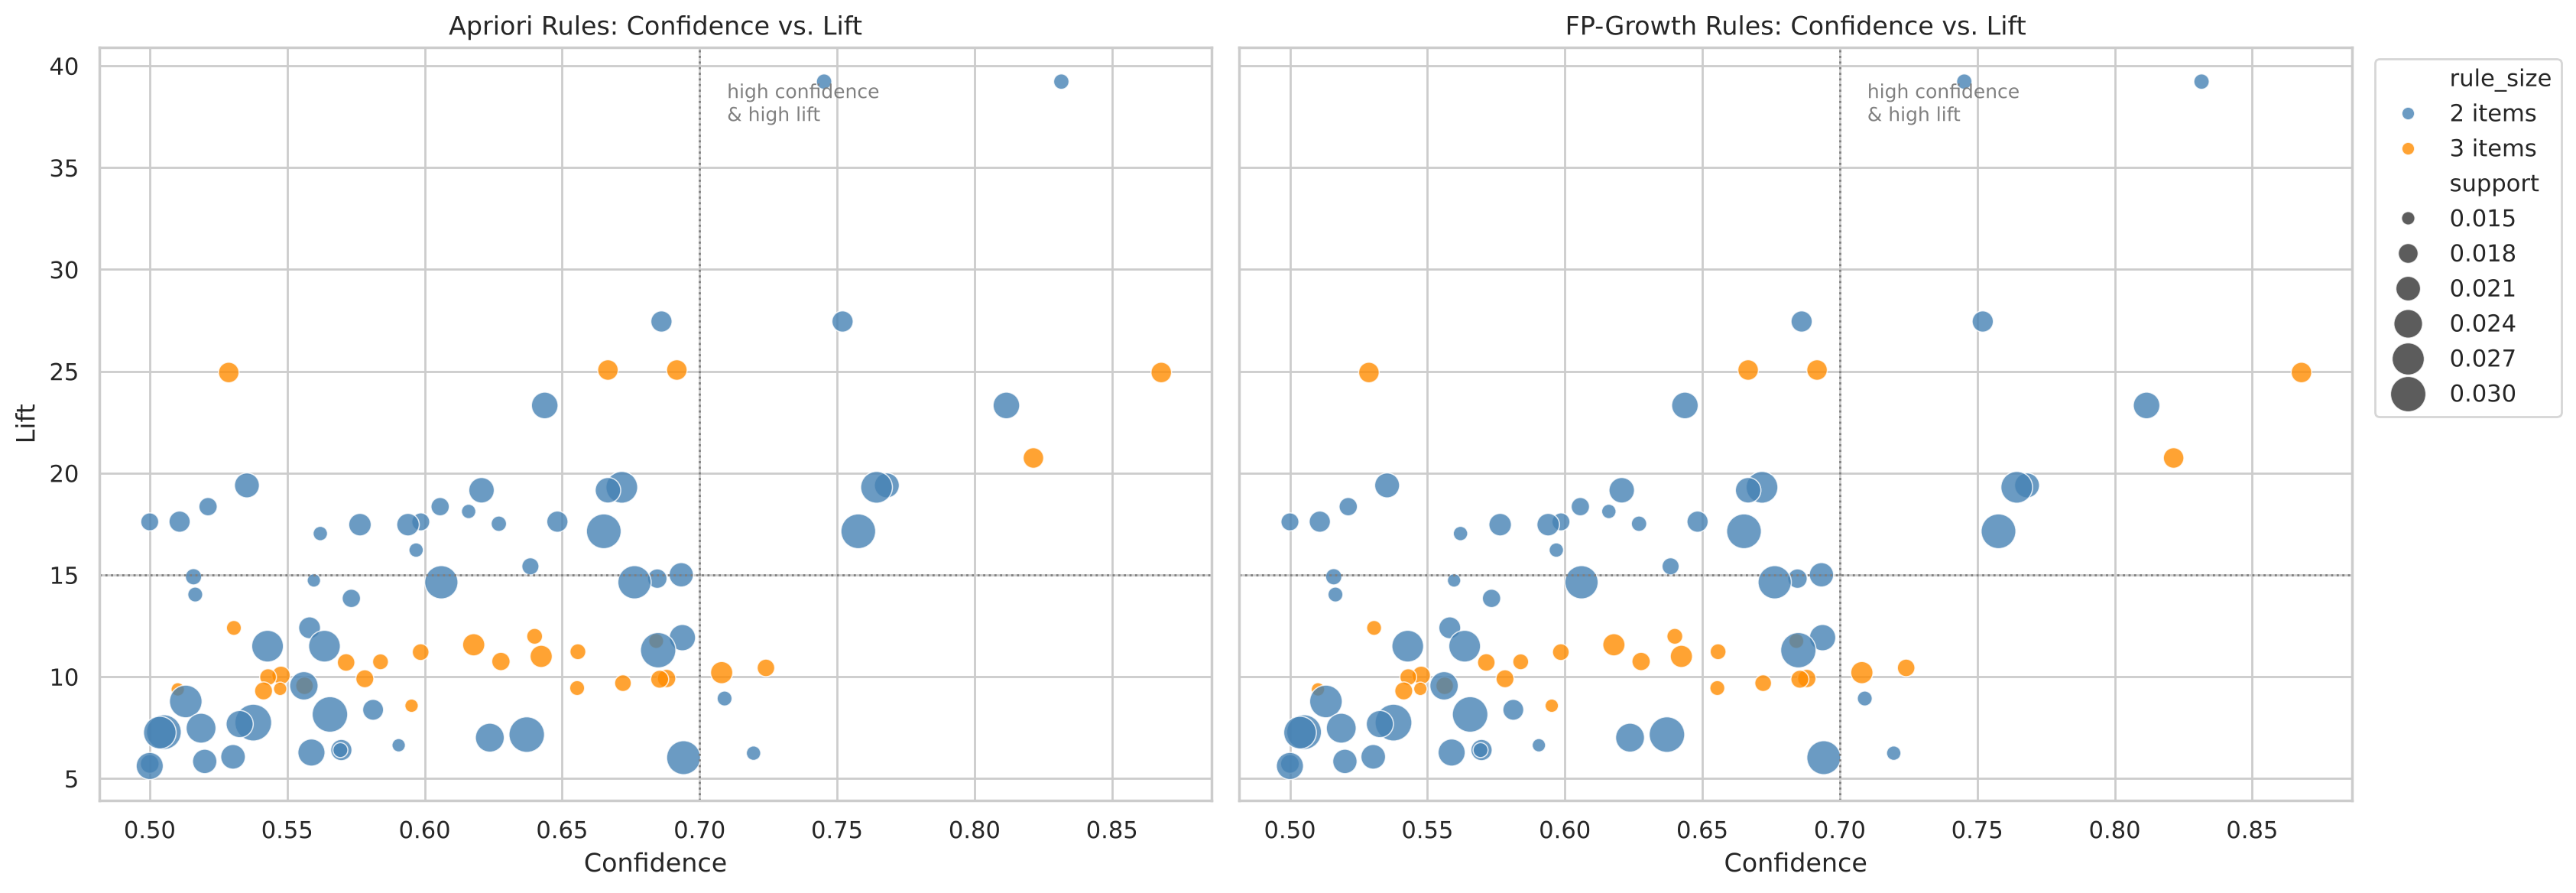

In [25]:
# Confidence vs. lift for both algorithms (point size = support) – side by side
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
for ax, rules, title in [(axes[0], apriori_rules, "Apriori"), (axes[1], fp_rules, "FP-Growth")]:
    sns.scatterplot(data=rules, x="confidence", y="lift", size="support", hue="rule_size",
                    sizes=(40, 300), palette={"2 items": "steelblue", "3 items": "darkorange"},
                    alpha=0.8, ax=ax)
    ax.axvline(0.7, color="grey", linestyle=":", linewidth=1)
    ax.axhline(15, color="grey", linestyle=":", linewidth=1)
    ax.text(0.71, rules["lift"].max(), "high confidence\n& high lift", va="top", fontsize=9, color="grey")
    ax.set_title(f"{title} Rules: Confidence vs. Lift")
    ax.set_xlabel("Confidence")
    ax.set_ylabel("Lift")
axes[0].get_legend().remove()                                   # one shared legend is enough
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))      # keep it off the data points
plt.tight_layout()
plt.show()

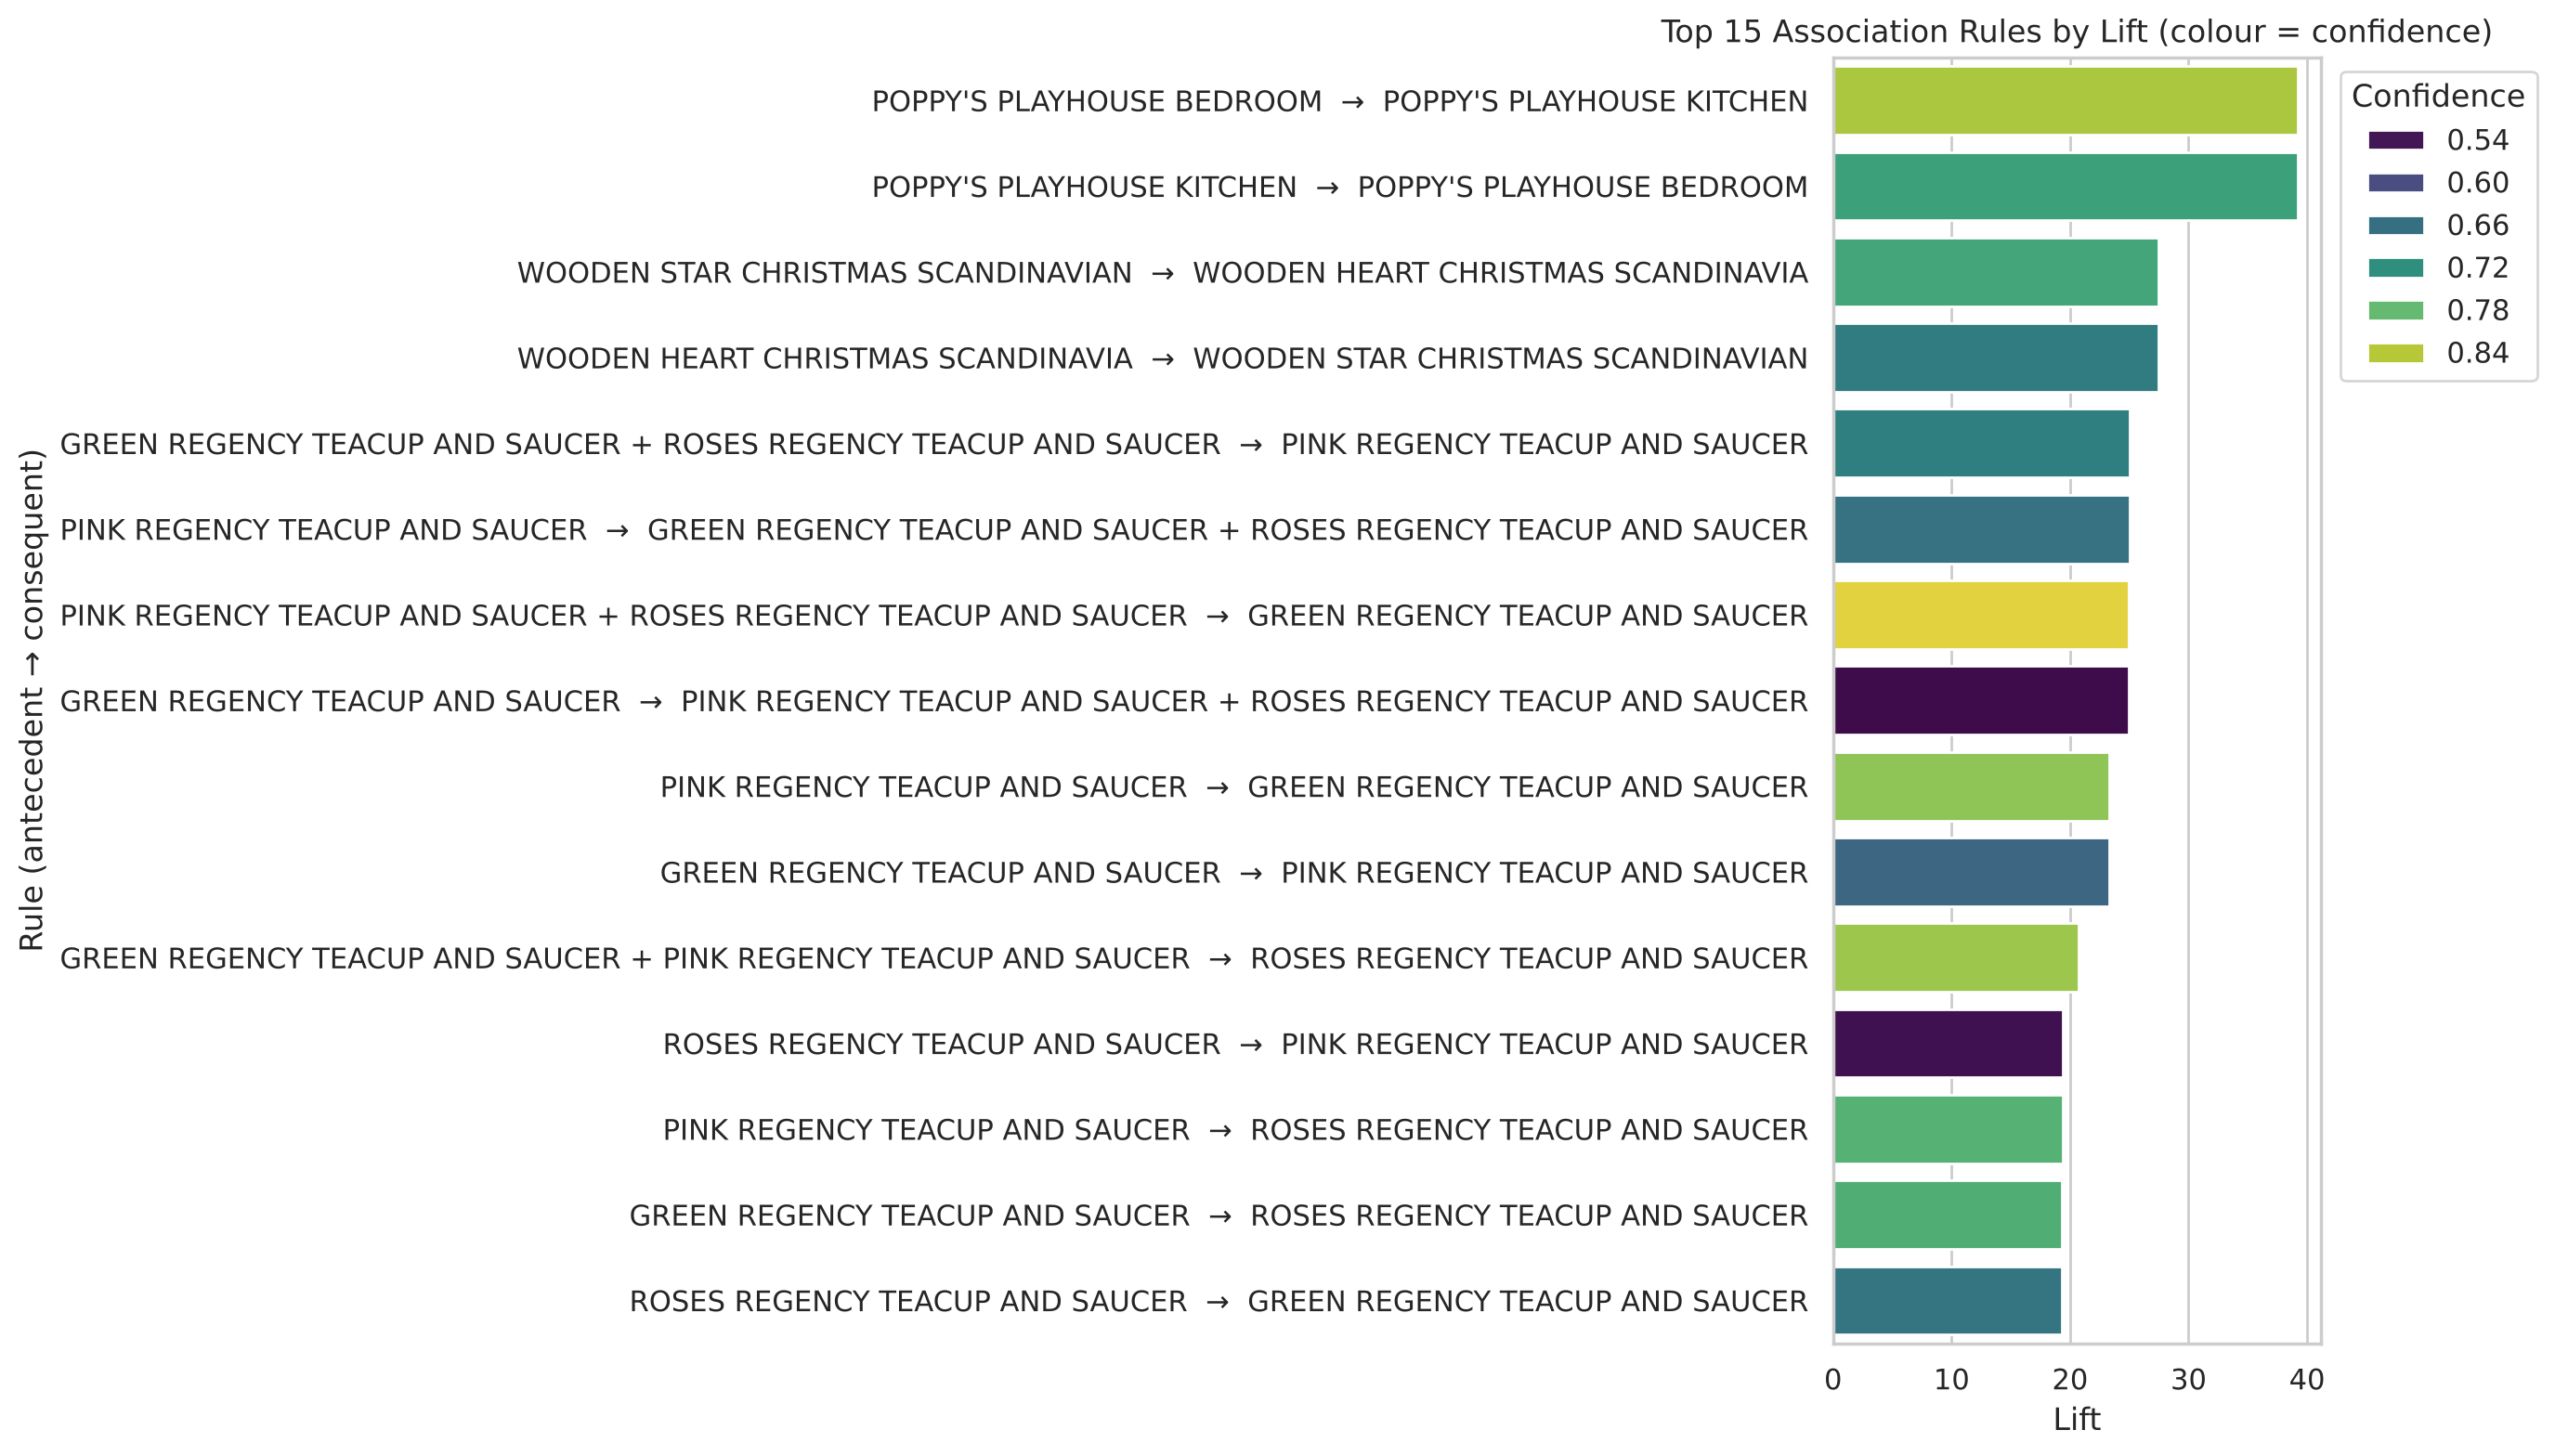

In [26]:
# Top 15 rules by lift, coloured by confidence
top_rules = apriori_rules.head(15)

plt.figure(figsize=(14, 8))
sns.barplot(data=top_rules, x="lift", y="rule", hue="confidence", palette="viridis", dodge=False)
plt.title("Top 15 Association Rules by Lift (colour = confidence)")
plt.xlabel("Lift")
plt.ylabel("Rule (antecedent → consequent)")
plt.legend(title="Confidence", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

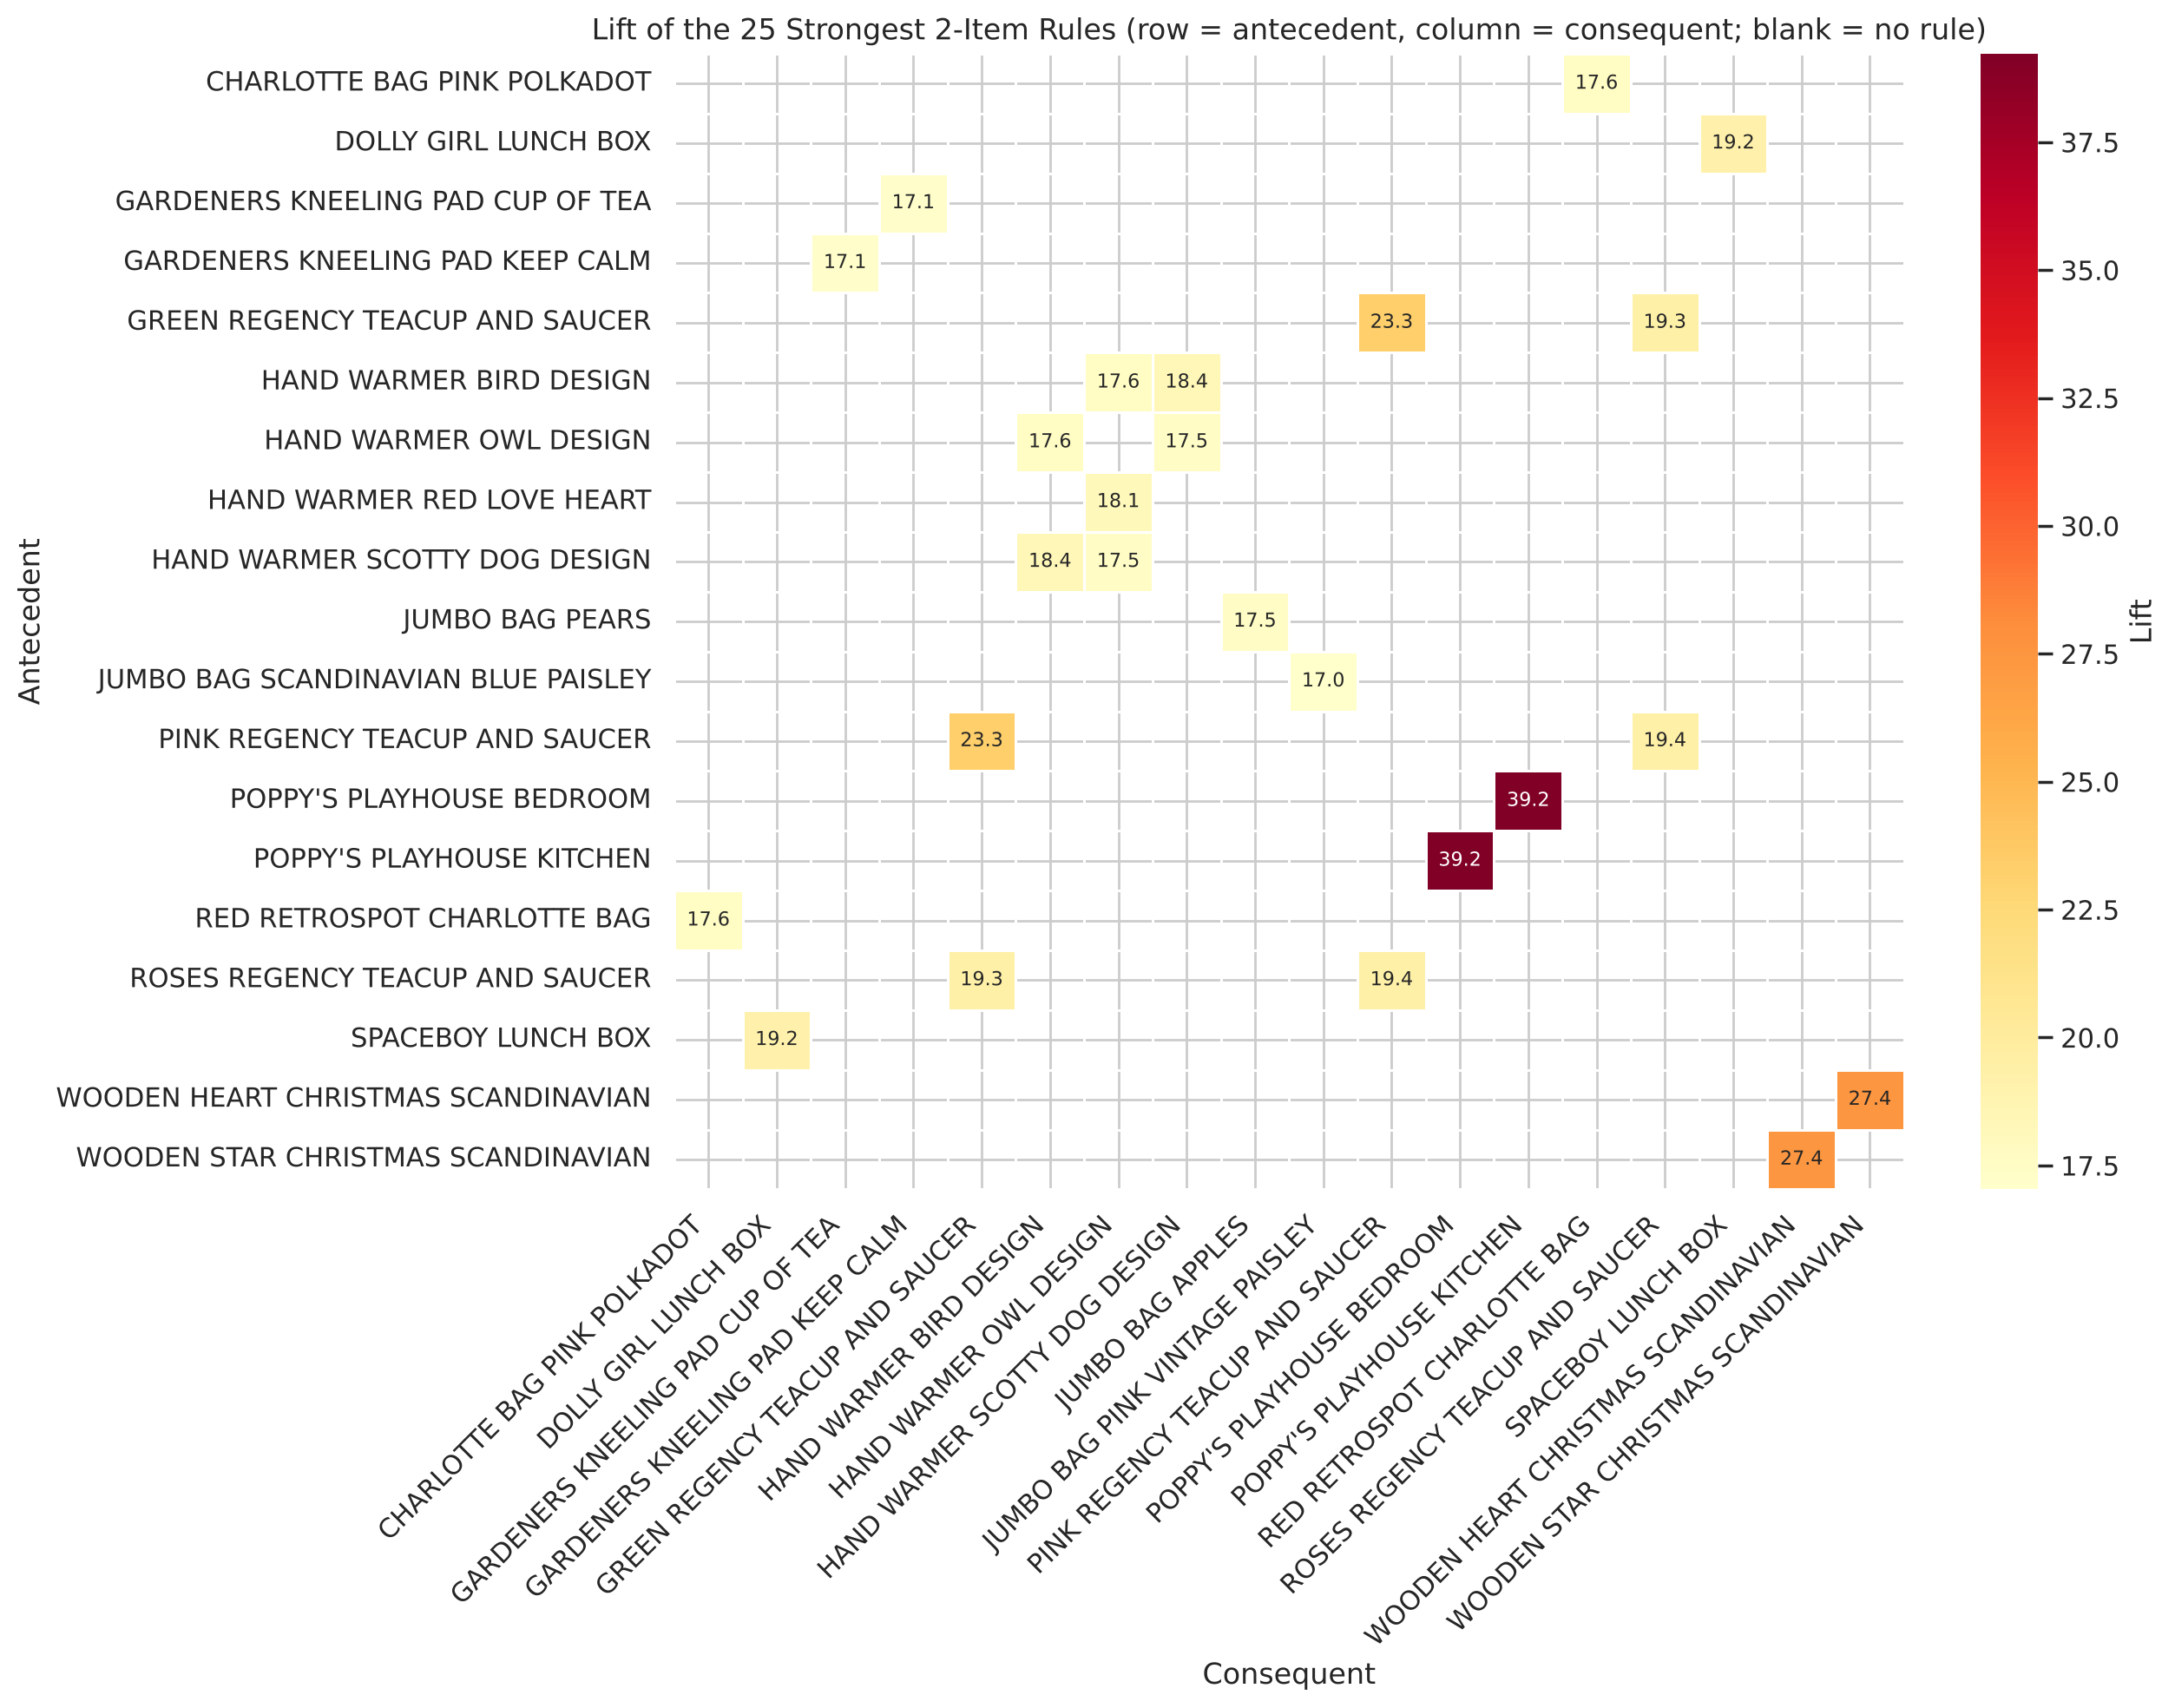

In [27]:
# Lift heatmap for the 25 strongest 2-item rules: which product predicts which
pair_rules = apriori_rules[apriori_rules["rule_size"] == "2 items"].head(25).copy()
pair_rules["A"] = pair_rules["antecedents"].apply(lambda s: label(s, 36))
pair_rules["B"] = pair_rules["consequents"].apply(lambda s: label(s, 36))
lift_matrix = pair_rules.pivot_table(index="A", columns="B", values="lift")

plt.figure(figsize=(13, 10))
sns.heatmap(lift_matrix, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.5,
            cbar_kws={"label": "Lift"}, annot_kws={"size": 8})
plt.title("Lift of the 25 Strongest 2-Item Rules (row = antecedent, column = consequent; blank = no rule)")
plt.xlabel("Consequent")
plt.ylabel("Antecedent")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [28]:
# Plain-language reading of the five strongest rules
for i, r in apriori_rules.head(5).iterrows():
    print(f"Rule {i + 1}: customers who buy {label(r['antecedents'])}")
    print(f"        also buy {label(r['consequents'])}")
    print(f"        support = {r['support']:.3f}, confidence = {r['confidence']:.1%}, lift = {r['lift']:.1f}\n")

Rule 1: customers who buy POPPY'S PLAYHOUSE BEDROOM
        also buy POPPY'S PLAYHOUSE KITCHEN
        support = 0.016, confidence = 83.2%, lift = 39.2

Rule 2: customers who buy POPPY'S PLAYHOUSE KITCHEN
        also buy POPPY'S PLAYHOUSE BEDROOM
        support = 0.016, confidence = 74.5%, lift = 39.2

Rule 3: customers who buy WOODEN STAR CHRISTMAS SCANDINAVIAN
        also buy WOODEN HEART CHRISTMAS SCANDINAVIAN
        support = 0.019, confidence = 75.2%, lift = 27.4

Rule 4: customers who buy WOODEN HEART CHRISTMAS SCANDINAVIAN
        also buy WOODEN STAR CHRISTMAS SCANDINAVIAN
        support = 0.019, confidence = 68.6%, lift = 27.4

Rule 5: customers who buy GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER
        also buy PINK REGENCY TEACUP AND SAUCER
        support = 0.018, confidence = 69.2%, lift = 25.1



**Interpreting the rules**

At confidence ≥ 0.5, both algorithms produce the **same 91 rules** (62 two-item rules and 29 three-item rules).
**Every rule has lift > 1** (min 5.6, median 11.6, max 39.2), so all of them are genuine positive associations rather
than artifacts of popular items. Confidence ranges from 0.50 to 0.87.

Key patterns:
1. **Collections are bought together.** The strongest rule is *Poppy's Playhouse Bedroom → Poppy's Playhouse Kitchen*
   (confidence 83%, **lift 39**). Customers who buy one room of this toy playhouse are 39× more likely than average to
   buy another. The *Wooden Star / Wooden Heart Christmas Scandinavian* decorations (lift 27) follow the same pattern.
2. **The Regency teacup trio is the clearest 3-item pattern.** *Pink + Roses Regency Teacup → Green Regency Teacup* has
   the **highest confidence of all rules (87%)** with lift 25. Owning two colours almost guarantees the third.
3. **Lunch bags and jumbo bags act as hubs.** *Lunch Bag Red Retrospot* is the consequent of **14 rules** and *Jumbo
   Bag Red Retrospot* of **8**. Buyers of almost any other lunch-bag or jumbo-bag design also pick up the red
   retrospot version. Lift is lower here (about 6–10) because the red retrospot bags are popular in their own right.
4. **Seasonal sets.** Hand warmers (bird, owl, Scotty dog, red heart designs; lift ≈ 17–18), Christmas paper-chain kits
   and the gardeners' kneeling pads all show the same "buy several designs together" pattern.
5. **The weakest rules (lift ≈ 6)** link related products rather than variants, for example
   *Green Regency Teacup → Regency Cakestand 3 Tier* and *Red Hanging Heart → White Hanging Heart T-Light Holder*.

**Reading the scatter plot.** The dotted lines mark confidence 0.7 and lift 15. The **9 rules in the top-right
quadrant** (high confidence *and* high lift) are the most actionable: the Poppy's Playhouse, Scandinavian Christmas
and Regency teacup rules. High-support rules (larger points) are mostly lunch-bag rules with moderate lift, so they are
reliable but less surprising.

**Business use:**
- Show "complete the set" recommendations for the Regency, Poppy's Playhouse and Scandinavian collections.
- Bundle lunch-bag and jumbo-bag designs as multipacks.
- Place the hand-warmer and Christmas sets together on the site and in pre-Christmas campaigns.

## Step 5: Comparative Analysis

In [29]:
# Final side-by-side summary
summary = pd.DataFrame({
    "Metric": ["Median runtime (s)", "Frequent itemsets", "1-item", "2-item", "3-item",
               "Rules (confidence >= 0.5)", "Identical itemsets", "Identical rules"],
    "Apriori": [round(apriori_time, 3), len(apriori_itemsets),
                *[(apriori_itemsets["length"] == k).sum() for k in (1, 2, 3)],
                len(apriori_rules), "-", "-"],
    "FP-Growth": [round(fpgrowth_time, 3), len(fpgrowth_itemsets),
                  *[(fpgrowth_itemsets["length"] == k).sum() for k in (1, 2, 3)],
                  len(fp_rules), not only_apriori and not only_fp, same_rules],
})
faster = "FP-Growth" if fpgrowth_time < apriori_time else "Apriori"
ratio = max(apriori_time, fpgrowth_time) / min(apriori_time, fpgrowth_time)
print(f"{faster} was faster at min_support = {min_support}, by a factor of {ratio:.1f}x (median of {n_runs} runs).")
summary

FP-Growth was faster at min_support = 0.015, by a factor of 16.0x (median of 5 runs).


,Metric,Apriori,FP-Growth
0,Median runtime (s),3.718,0.233
1,Frequent itemsets,466,466
2,1-item,357,357
3,2-item,100,100
4,3-item,9,9
5,Rules (confidence >= 0.5),91,91
6,Identical itemsets,-,True
7,Identical rules,-,True


### Results comparison

| | Apriori | FP-Growth |
|---|---|---|
| Frequent itemsets (min_support 0.015) | 466 | 466 (identical) |
| Rules (confidence ≥ 0.5) | 91 | 91 (identical) |
| Median runtime | ≈ 3.7 s | ≈ 0.25 s |

Both algorithms are exact, so they always agree on the itemsets, the support values and therefore the rules.
The only real difference is efficiency.

### Which algorithm was faster, and why?
**FP-Growth was faster: about 15× at the chosen threshold, and about 30× at min_support = 0.01.**

- **Apriori uses candidate generation and testing, level by level.** It first finds frequent single items, then
  generates every candidate pair from them and counts each candidate against all 5,000 transactions, then repeats for
  triples.
  - With 357 frequent items, there are 357 × 356 / 2 ≈ **63,500 candidate pairs** to count, yet only 100 turn out to be
    frequent.
  - Each level needs another full pass over the data. In `mlxtend`, it also needs a large in-memory boolean array of
    candidates × transactions.
  - Lowering the support increases the number of frequent items, so the candidate count grows roughly quadratically.
    This is the steep curve in the runtime-vs-support plot.
- **FP-Growth avoids candidate generation.** It scans the data twice: once to count item frequencies, and once to
  insert each transaction (with infrequent items removed and the rest sorted by frequency) into a compact prefix tree,
  the **FP-tree**. Transactions that share popular items share tree branches. The tree is then mined recursively
  through *conditional pattern bases*, so the algorithm only explores item combinations that actually occur together.
- **Why the effect is large on this dataset:** the basket matrix is about 99.4% empty, with thousands of items but only
  about 15 per basket. Most of Apriori's candidate pairs never occur together, and it still counts every one of them.
  FP-Growth only touches combinations that exist in the tree.
- **When Apriori is competitive:** at high support (0.04), there are so few frequent items that both finish in under
  0.1 s. Apriori's cost only explodes when the problem gets harder.

### Challenges faced and how they were resolved

1. **Dataset size and memory.** Over 18,000 cleaned invoices × about 3,900 products creates a very wide one-hot matrix,
   and Apriori's candidate arrays grow quickly on top of it.
   *Resolution:* focused on UK customers (90% of invoices) and drew a reproducible random sample of 5,000 invoices
   (`random_state=42`). The matrix was stored as booleans rather than integers, and `max_len = 3` caps candidate growth.
2. **Dirty transactional data.** The data contained cancellations, negative quantities, zero and negative prices,
   missing customer IDs, duplicate rows, and non-product codes such as postage and manual adjustments. Left in, these
   would create fake items such as "POSTAGE" and spurious rules.
   *Resolution:* applied the six-step cleaning pipeline in 1.4 and logged the rows removed at each step.
3. **Inconsistent product names.** Some descriptions carry trailing spaces, which would split one product into two items.
   *Resolution:* stripped whitespace before building the basket.
4. **Choosing the support threshold.** The data is so sparse that common textbook thresholds (5–10%) returned only
   single items and no rules.
   *Resolution:* ran a support sweep and chose 0.015, the highest value that still produces 3-item itemsets.
5. **Making the speed comparison fair.** A single timing run is noisy.
   *Resolution:* gave both algorithms identical inputs and parameters, timed each 5 times with `time.perf_counter()`,
   reported the median, and added a runtime-vs-support sweep.
6. **Verifying the outputs really match.** Equal counts do not prove equal results.
   *Resolution:* compared the itemsets as sets of `frozenset`s, together with their support values, and compared the
   rule sets the same way.
7. **Readability.** Long product names made the charts unreadable, and library deprecation warnings cluttered the
   output.
   *Resolution:* shortened labels in the charts and suppressed warnings in the import cell.
8. **Dataset download.** The UCI download link is occasionally unavailable.
   *Resolution:* the loader falls back to an identical copy of the dataset hosted on GitHub.

### Conclusion
Association rule mining on the UCI Online Retail data shows that this retailer's customers buy **coordinated
collections**: multiple colours or designs of the same teacup, lunch bag, jumbo bag, hand warmer, playhouse or
Christmas decoration. These rules have very high lift (up to 39), which points directly to cross-selling and bundling
opportunities. Apriori and FP-Growth produced identical itemsets and rules, as exact algorithms should. FP-Growth was
consistently and substantially faster on this large, sparse dataset because it compresses the transactions into an
FP-tree instead of generating and counting candidate itemsets.